# Dual-Adversary Multi-Attribute Suppression on CelebA

**Research contribution:**
- Task attribute: `Smiling` (preserve utility)
- Private attribute 1: `Male` (suppress)
- Private attribute 2: `Young` (suppress)
- Novel: 2D (λ₁, λ₂) Pareto surface + independent adversary evaluation + correlation conflict analysis

**Platform:** Kaggle (P100 GPU · 30 hr/week free)
**Before running:** Settings → Accelerator → GPU P100 · Add dataset → jessicali9530/celeba-dataset

## GPU check & FP16

In [1]:
import tensorflow as tf
import sys

tf.keras.mixed_precision.set_global_policy('float32')

print(f'Python     : {sys.version.split()[0]}')
print(f'TensorFlow : {tf.__version__}')
# print(f'GPU        : {gpus[0].name}')
print(f'Precision  : {tf.keras.mixed_precision.global_policy().name}')
print('OK')

2026-04-11 06:07:17.332487: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775887637.858135      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775887638.008691      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775887639.238681      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775887639.238733      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775887639.238736      55 computation_placer.cc:177] computation placer alr

Python     : 3.12.12
TensorFlow : 2.19.0
Precision  : float32
OK


## Install & imports

In [2]:
!pip install -q scikit-image

import os, gc, json, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim
warnings.filterwarnings('ignore')

from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (
    Conv2D, Conv2DTranspose, MaxPooling2D,
    Dense, GlobalAveragePooling2D, Dropout,
    BatchNormalization, LeakyReLU, Flatten,
    Concatenate, Reshape
)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
import tensorflow.keras.backend as K

print('Imports OK')

Imports OK


## Global config

In [4]:
# ── Paths ────────────────────────────────────────────────────
PROJECT_DIR = '/kaggle/working/adv_privacy_celeba'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
LOG_DIR     = f'{PROJECT_DIR}/logs'
PLOT_DIR    = f'{PROJECT_DIR}/plots'
DATA_DIR    = '/kaggle/input/datasets/jessicali9530/celeba-dataset'

for d in [PROJECT_DIR, CKPT_DIR, LOG_DIR, PLOT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Hyperparameters ──────────────────────────────────────────
IMG_SIZE    = 96
BATCH_SIZE  = 32
N_SAMPLES   = 30000
RANDOM_SEED = 42
KL_WEIGHT   = 0.0

# ── Attribute roles ──────────────────────────────────────────
TASK_ATTR     = 'Smiling'
PRIVATE_ATTR1 = 'Male'
PRIVATE_ATTR2 = 'Young'

# ── Lambda grid for 2D sweep (5x5 = 25 points) ───────────────
LAMBDA_VALUES = [0.0, 0.25, 0.5, 0.75, 1.0]
SWEEP_EPOCHS  = 8

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print('Config set')
print(f'  IMG_SIZE  : {IMG_SIZE}x{IMG_SIZE}')
print(f'  N_SAMPLES : {N_SAMPLES:,}')
print(f'  Task      : {TASK_ATTR}')
print(f'  Private1  : {PRIVATE_ATTR1}')
print(f'  Private2  : {PRIVATE_ATTR2}')
print(f'  Grid      : {len(LAMBDA_VALUES)}x{len(LAMBDA_VALUES)} = {len(LAMBDA_VALUES)**2} sweep points')

Config set
  IMG_SIZE  : 96x96
  N_SAMPLES : 30,000
  Task      : Smiling
  Private1  : Male
  Private2  : Young
  Grid      : 5x5 = 25 sweep points


In [5]:
# ── Persistent output directory ───────────────────────────────

OUTPUT_CKPT = '/kaggle/working/saved_checkpoints'
os.makedirs(OUTPUT_CKPT, exist_ok=True)

def save_to_output(tag, include_sweep_log=False):
    """Copy model checkpoints to persistent output directory."""
    for name in ['anon', 'cls', 'adv1', 'adv2']:
        src = f'{CKPT_DIR}/{name}_{tag}.weights.h5'
        dst = f'{OUTPUT_CKPT}/{name}_{tag}.weights.h5'
        if os.path.exists(src):
            shutil.copy2(src, dst)
    if include_sweep_log:
        src = f'{LOG_DIR}/sweep_results.json'
        dst = f'{OUTPUT_CKPT}/sweep_results.json'
        if os.path.exists(src):
            shutil.copy2(src, dst)
    print(f'Saved [{tag}] to output')

def save_single(src_path, filename):
    """Copy any single file to persistent output directory."""
    dst = f'{OUTPUT_CKPT}/{filename}'
    if os.path.exists(src_path):
        shutil.copy2(src_path, dst)
        print(f'Saved [{filename}] to output')
    else:
        print(f'WARNING: {src_path} not found — nothing saved')

print('Persistence helpers ready')
print(f'Output directory : {OUTPUT_CKPT}')

Persistence helpers ready
Output directory : /kaggle/working/saved_checkpoints


## Verify CelebA dataset

CelebA is pre-mounted on Kaggle.
Added `jessicali9530/celeba-dataset` via the **Add data** panel before running.

In [6]:
import os

DATA_DIR = '/kaggle/input/datasets/jessicali9530/celeba-dataset'

def find_path(base, filename):
    """Recursively search for a file or folder under base."""
    for root, dirs, files in os.walk(base):
        if filename in files or filename in dirs:
            return os.path.join(root, filename)
    return None

IMG_DIR   = find_path(DATA_DIR, 'img_align_celeba')
ATTR_FILE = find_path(DATA_DIR, 'list_attr_celeba.csv')

if IMG_DIR and os.path.isdir(IMG_DIR):
    sample = os.listdir(IMG_DIR)[:5]
    if not any(f.endswith('.jpg') for f in sample):
        inner = os.path.join(IMG_DIR, 'img_align_celeba')
        if os.path.isdir(inner):
            IMG_DIR = inner

assert IMG_DIR   and os.path.isdir(IMG_DIR),   f'img_align_celeba not found under {DATA_DIR}'
assert ATTR_FILE and os.path.isfile(ATTR_FILE), f'list_attr_celeba.csv not found under {DATA_DIR}'

n_imgs = len(os.listdir(IMG_DIR))
print(f'CelebA images found : {n_imgs:,}')
print(f'Images path         : {IMG_DIR}')
print(f'Attribute CSV       : {ATTR_FILE}')
print('Dataset ready')

CelebA images found : 202,599
Images path         : /kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba
Attribute CSV       : /kaggle/input/datasets/jessicali9530/celeba-dataset/list_attr_celeba.csv
Dataset ready


## Load attributes & build split

In [7]:
attr_df = pd.read_csv(ATTR_FILE)

# CelebA uses -1/+1 encoding → convert to 0/1
for col in attr_df.columns[1:]:
    attr_df[col] = (attr_df[col] == 1).astype(int)

subset = attr_df.head(N_SAMPLES).copy()

print(f'Attribute table : {attr_df.shape}')
print(f'\nClass balance in {N_SAMPLES:,} sample:')
for attr in [TASK_ATTR, PRIVATE_ATTR1, PRIVATE_ATTR2]:
    pct = subset[attr].mean() * 100
    print(f'  {attr:12s} : {pct:.1f}% positive')

# Correlation between private attributes — key for Layer 3 analysis
corr = subset[[PRIVATE_ATTR1, PRIVATE_ATTR2]].corr().iloc[0, 1]
print(f'\nCorrelation {PRIVATE_ATTR1} vs {PRIVATE_ATTR2} : {corr:.3f}')
print('Non-zero correlation = joint suppression is non-trivial')

Attribute table : (202599, 41)

Class balance in 30,000 sample:
  Smiling      : 47.5% positive
  Male         : 42.3% positive
  Young        : 77.9% positive

Correlation Male vs Young : -0.288
Non-zero correlation = joint suppression is non-trivial


In [8]:
filenames = [
    f'{IMG_DIR}/{fname}'
    for fname in subset['image_id'].values
]

# Standard 32-bit label generation
task_labels  = subset[TASK_ATTR].values.astype('float32')
priv1_labels = subset[PRIVATE_ATTR1].values.astype('float32')
priv2_labels = subset[PRIVATE_ATTR2].values.astype('float32')

# 75% train / 12.5% val / 12.5% test — stratified on task label
X_tv, X_test, yt_tv, yt_test, yp1_tv, yp1_test, yp2_tv, yp2_test = \
    train_test_split(filenames, task_labels, priv1_labels, priv2_labels,
                     test_size=0.125, random_state=RANDOM_SEED,
                     stratify=task_labels)

X_train, X_val, yt_train, yt_val, yp1_train, yp1_val, yp2_train, yp2_val = \
    train_test_split(X_tv, yt_tv, yp1_tv, yp2_tv,
                     test_size=1/7, random_state=RANDOM_SEED,
                     stratify=yt_tv)

print(f'Train : {len(X_train):,}  Val : {len(X_val):,}  Test : {len(X_test):,}')

Train : 22,500  Val : 3,750  Test : 3,750


## tf.data streaming pipeline

Images are never all loaded into RAM simultaneously.
Only the active batch and prefetch buffer are in memory at any time.

In [9]:
def load_image(filepath, t, p1, p2):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, t, p1, p2

def augment(img, t, p1, p2):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, 0.08)
    img = tf.image.random_contrast(img, 0.92, 1.08)
    img = tf.clip_by_value(img, 0.0, 1.0)
    return img, t, p1, p2

def make_ds(paths, tl, p1l, p2l, shuffle=False, aug=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, tl, p1l, p2l))
    if shuffle:
        ds = ds.shuffle(2048, seed=RANDOM_SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if aug:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, yt_train, yp1_train, yp2_train, shuffle=True, aug=True)
val_ds   = make_ds(X_val,   yt_val,   yp1_val,   yp2_val)
test_ds  = make_ds(X_test,  yt_test,  yp1_test,  yp2_test)

# Sanity check
for imgs, tl, p1l, p2l in train_ds.take(1):
    print(f'Batch shape : {imgs.shape}  dtype: {imgs.dtype}')
    print(f'Task   [{TASK_ATTR}]   : {tl.numpy()[:8]}')
    print(f'Priv1  [{PRIVATE_ATTR1}]    : {p1l.numpy()[:8]}')
    print(f'Priv2  [{PRIVATE_ATTR2}]    : {p2l.numpy()[:8]}')
print('Streaming pipeline ready')

I0000 00:00:1775887714.563501      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Batch shape : (32, 96, 96, 3)  dtype: <dtype: 'float32'>
Task   [Smiling]   : [0. 1. 1. 1. 0. 1. 1. 0.]
Priv1  [Male]    : [1. 1. 0. 0. 1. 0. 0. 0.]
Priv2  [Young]    : [1. 0. 1. 1. 0. 1. 1. 1.]
Streaming pipeline ready


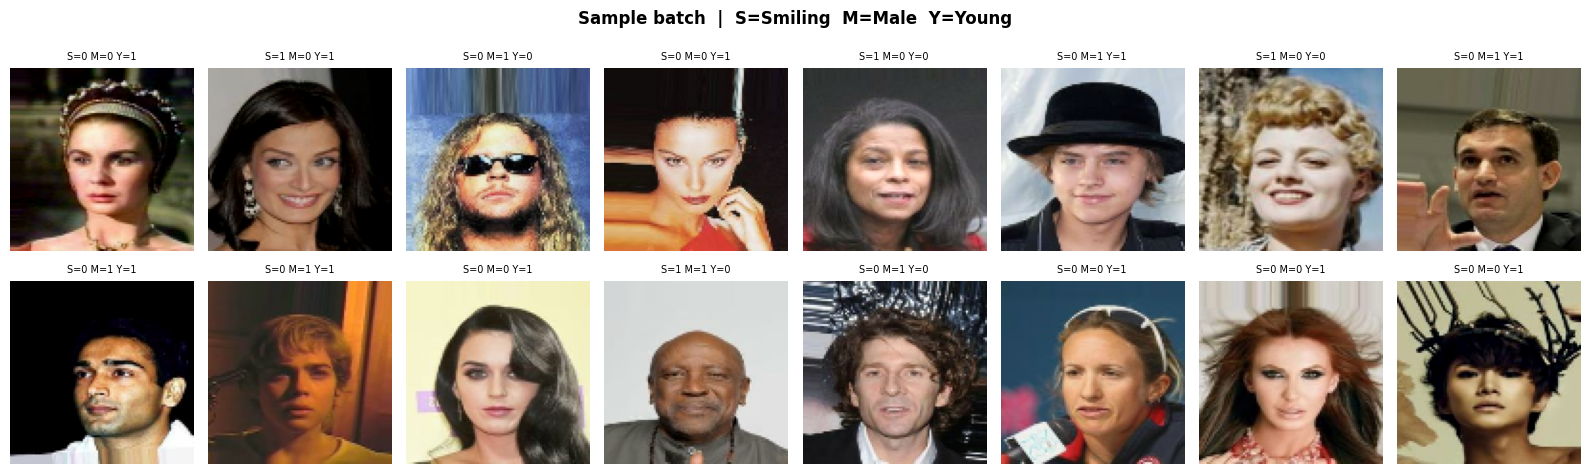

In [10]:
# Visual sanity check
sample_imgs, sample_t, sample_p1, sample_p2 = next(iter(train_ds))

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i in range(8):
    for row, idx in enumerate([i, i+8]):
        axes[row, i].imshow(sample_imgs[idx].numpy())
        axes[row, i].set_title(
            f'S={int(sample_t[idx])} M={int(sample_p1[idx])} Y={int(sample_p2[idx])}',
            fontsize=7)
        axes[row, i].axis('off')

plt.suptitle('Sample batch  |  S=Smiling  M=Male  Y=Young', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/cell5_sample.png', dpi=120, bbox_inches='tight')
plt.show()

## Model definitions

**Anonymizer:** U-Net with skip connections + variational bottleneck. Skip connections give fine-grained spatial control. Variational bottleneck makes noise injection a learnable, stable operation.

**SamplingLayer** replaces `Lambda(sampling)` to fix shape inference under Keras 3 + FP16.

**Adversaries:** Predict a private attribute (not real/fake). If accuracy → 50% the anonymizer has succeeded.

**Bottleneck size** is computed dynamically from `IMG_SIZE` so the model works at 64, 96, or 128 without shape mismatches.

In [12]:
class SamplingLayer(tf.keras.layers.Layer):
    """Kept for compatibility — no longer used in anonymizer."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        z_mean    = tf.cast(z_mean,    tf.float32)
        z_log_var = tf.cast(z_log_var, tf.float32)
        epsilon   = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon
    def compute_output_shape(self, input_shape):
        return input_shape[0]


def build_anonymizer(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    inp = Input(shape=input_shape, name='anon_in')

    # ── Encoder ──────────────────────────────────────────────
    e1 = Conv2D(32,  3, activation='relu', padding='same')(inp)
    e1 = BatchNormalization()(e1)
    p1 = MaxPooling2D(2, padding='same')(e1)

    e2 = Conv2D(64,  3, activation='relu', padding='same')(p1)
    e2 = BatchNormalization()(e2)
    p2 = MaxPooling2D(2, padding='same')(e2)

    e3 = Conv2D(128, 3, activation='relu', padding='same')(p2)
    e3 = BatchNormalization()(e3)
    p3 = MaxPooling2D(2, padding='same')(e3)

    # ── Simple deterministic bottleneck — no VAE, no NaN ─────
    b = Conv2D(128, 3, activation='relu', padding='same')(p3)
    b = BatchNormalization()(b)

    # ── Decoder with skip connections ────────────────────────
    d3 = Conv2DTranspose(128, 3, strides=2, padding='same', activation='relu')(b)
    d3 = Concatenate()([d3, e3])
    d3 = BatchNormalization()(d3)

    d2 = Conv2DTranspose(64,  3, strides=2, padding='same', activation='relu')(d3)
    d2 = Concatenate()([d2, e2])
    d2 = BatchNormalization()(d2)

    d1 = Conv2DTranspose(32,  3, strides=2, padding='same', activation='relu')(d2)
    d1 = Concatenate()([d1, e1])

    out = Conv2D(3, 3, padding='same', activation='sigmoid', name='anon_out')(d1)

    return Model(inp, out, name='Anonymizer')


def build_classifier(trainable_base=False, unfreeze_last=20):
    base = MobileNetV2(weights='imagenet', include_top=False,
                       input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = trainable_base
    if trainable_base:
        for layer in base.layers[:-unfreeze_last]:
            layer.trainable = False
    x   = GlobalAveragePooling2D()(base.output)
    x   = Dense(128, activation='relu')(x)
    x   = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid', name='cls_out')(x)
    return Model(base.input, out, name='Classifier')


def build_adversary(name='Adversary'):
    """✅ FIXED: Balanced capacity with proper pooling"""
    inp = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    # Conv block 1: 96x96x3 → 48x48x32
    x = Conv2D(32, 4, strides=2, padding='same')(inp)
    x = LeakyReLU(0.2)(x)
    x = BatchNormalization()(x)
    
    # Conv block 2: 48x48x32 → 24x24x64
    x = Conv2D(64, 4, strides=2, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = BatchNormalization()(x)
    
    # ✅ ADD: Conv block 3 (but with SMALLER channels): 24x24x64 → 12x12x64
    x = Conv2D(64, 4, strides=2, padding='same')(x)  # Keep 64 channels (not 128!)
    x = LeakyReLU(0.2)(x)
    x = BatchNormalization()(x)
    
    # Dense layers: 12x12x64 = 9,216 features
    x = Flatten()(x)
    x = Dense(64)(x)  # 9,216 × 64 = ~590K params
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.3)(x)
    
    out = Dense(1, activation='sigmoid')(x)
    return Model(inp, out, name=name)




In [13]:
anonymizer = build_anonymizer()
classifier = build_classifier(trainable_base=False)
adversary1 = build_adversary(name='Adversary_Male')
adversary2 = build_adversary(name='Adversary_Young')

print('All models built')
print(f'  Anonymizer  : {anonymizer.count_params():>10,} params')
print(f'  Classifier  : {classifier.count_params():>10,} params')
print(f'  Adversary×2 : {adversary1.count_params():>10,} params each')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
All models built
  Anonymizer  :    577,507 params
  Classifier  :  2,422,081 params
  Adversary×2 :    690,593 params each


## Helper functions

In [16]:
bce = BinaryCrossentropy()

def kl_loss(z_mean, z_log_var):
    return 0.0

def binary_accuracy(y_true, y_pred):
    # Standard 32-bit accuracy calculation
    return tf.reduce_mean(
        tf.cast(tf.equal(
            tf.cast(y_pred > 0.5, tf.float32),
            tf.cast(y_true,       tf.float32)
        ), tf.float32)
    ).numpy()

def compute_ssim_batch(originals, anonymized):
    scores = []
    for o, a in zip(originals, anonymized):
        # Numpy safely handles the float16 to uint8 casting here
        og = cv2.cvtColor((o * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
        ag = cv2.cvtColor((a * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
        scores.append(ssim(og, ag, full=True)[0])
    return np.mean(scores)

def evaluate_on_test(anon_model, cls_model, adv1_model, adv2_model, dataset):
    """Full evaluation: cls accuracy, both adversary accuracies, SSIM."""
    cls_c = adv1_c = adv2_c = total = 0
    ssim_sum = 0.0
    for imgs, tl, p1l, p2l in dataset:
        # Fixed unpacking error (VAE removed)
        anon = anon_model(imgs, training=False)
        anon_np    = anon.numpy()
        cp  = cls_model(anon,  training=False).numpy().flatten()
        p1p = adv1_model(anon, training=False).numpy().flatten()
        p2p = adv2_model(anon, training=False).numpy().flatten()
        cls_c  += np.sum((cp  > 0.5) == tl.numpy())
        adv1_c += np.sum((p1p > 0.5) == p1l.numpy())
        adv2_c += np.sum((p2p > 0.5) == p2l.numpy())
        total  += len(imgs)
        ssim_sum += compute_ssim_batch(imgs.numpy(), anon_np) * len(imgs)
    n = total
    return {
        'cls_acc':     cls_c  / n,
        'adv1_acc':    adv1_c / n,
        'adv2_acc':    adv2_c / n,
        'priv1_score': 1.0 - adv1_c / n,
        'priv2_score': 1.0 - adv2_c / n,
        'ssim':        ssim_sum / n
    }

def save_checkpoint(tag):
    anonymizer.save_weights(f'{CKPT_DIR}/anon_{tag}.weights.h5')
    classifier.save_weights(f'{CKPT_DIR}/cls_{tag}.weights.h5')
    adversary1.save_weights(f'{CKPT_DIR}/adv1_{tag}.weights.h5')
    adversary2.save_weights(f'{CKPT_DIR}/adv2_{tag}.weights.h5')

def clear_memory():
    """Call between sweep iterations to prevent RAM accumulation."""
    K.clear_session()
    gc.collect()

print('Helper functions ready')

Helper functions ready


## Stage 1: Baseline classifier on original images

Trains on original (non-anonymized) images. This is the accuracy ceiling — anonymization will reduce it slightly. Target: >80%.

In [17]:
BASELINE_CKPT = f'{CKPT_DIR}/baseline_classifier.weights.h5'

cls_train = train_ds.map(lambda i, t, p1, p2: (i, t))
cls_val   = val_ds.map(lambda i, t, p1, p2:   (i, t))
cls_test  = test_ds.map(lambda i, t, p1, p2:  (i, t))

# Rebuild classifier with top 30 layers unfrozen
classifier = build_classifier(trainable_base=True, unfreeze_last=30)

classifier.compile(
    optimizer=Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print('Stage 1: Baseline classifier with top 30 layers unfrozen')
history_base = classifier.fit(
    cls_train,
    validation_data=cls_val,
    epochs=20,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            BASELINE_CKPT, save_weights_only=True,
            monitor='val_accuracy', save_best_only=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, verbose=1),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=6,
            restore_best_weights=True, verbose=1)
    ],
    verbose=1
)

classifier.load_weights(BASELINE_CKPT)
_, baseline_acc = classifier.evaluate(cls_test, verbose=0)
print(f'\nBaseline test accuracy : {baseline_acc*100:.1f}%')

# Save to persistent output immediately
save_single(BASELINE_CKPT, 'baseline_classifier.weights.h5')

Stage 1: Baseline classifier with top 30 layers unfrozen
Epoch 1/20


I0000 00:00:1775887798.923138     135 service.cc:152] XLA service 0x2de6ea00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775887798.923176     135 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1775887800.693573     135 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-11 06:10:05.362364: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-11 06:10:05.545067: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-11 06:10:05.806765: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy.

703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7009 - loss: 0.5643

2026-04-11 06:10:56.698098: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-11 06:10:56.880020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 92ms/step - accuracy: 0.7011 - loss: 0.5641 - val_accuracy: 0.7205 - val_loss: 0.6655 - learning_rate: 1.0000e-04
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8317 - loss: 0.3756 - val_accuracy: 0.8309 - val_loss: 0.3792 - learning_rate: 1.0000e-04
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8584 - loss: 0.3215 - val_accuracy: 0.8267 - val_loss: 0.3936 - learning_rate: 1.0000e-04
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.8827 - loss: 0.2697 - val_accuracy: 0.7821 - val_loss: 0.5691 - learning_rate: 1.0000e-04
Epoch 5/20
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9057 - loss: 0.2218
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9058 - loss: 0.2217 - val_accuracy: 0.8277 - val_loss: 0.4761 - learning_rate: 1.0000e-04
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9

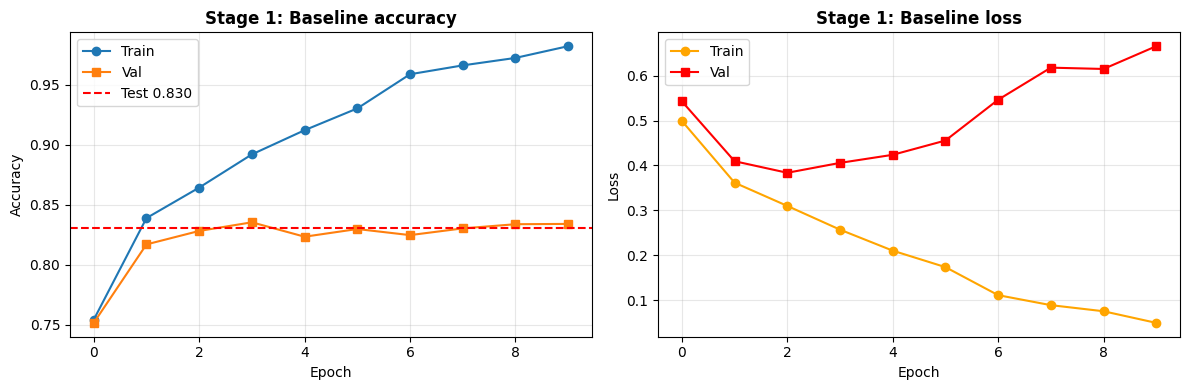

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_base.history['accuracy'],     label='Train', marker='o')
ax[0].plot(history_base.history['val_accuracy'], label='Val',   marker='s')
ax[0].axhline(baseline_acc, color='red', linestyle='--', label=f'Test {baseline_acc:.3f}')
ax[0].set_title('Stage 1: Baseline accuracy', fontweight='bold')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(history_base.history['loss'],     label='Train', color='orange', marker='o')
ax[1].plot(history_base.history['val_loss'], label='Val',   color='red',    marker='s')
ax[1].set_title('Stage 1: Baseline loss', fontweight='bold')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/stage1_baseline.png', dpi=120, bbox_inches='tight')
plt.show()

## Stage 2: Pre-train both adversaries on original images

Pre-training on original images gives adversaries a strong starting point so the privacy loss signal is meaningful from epoch 1 of adversarial training. Also establishes the ceiling: how well the adversary does when no anonymization has happened yet.

In [20]:
import os

# Delete old adversary weights from the WORKING directory (not input)
adv1_ckpt = f'{CKPT_DIR}/adv1_pretrained.weights.h5'
adv2_ckpt = f'{CKPT_DIR}/adv2_pretrained.weights.h5'

if os.path.exists(adv1_ckpt):
    os.remove(adv1_ckpt)
    print("Deleted old adv1 weights")

if os.path.exists(adv2_ckpt):
    os.remove(adv2_ckpt)
    print("Deleted old adv2 weights")

print("✅ Old adversary weights cleared - ready to retrain in Stage 2")

Deleted old adv1 weights
✅ Old adversary weights cleared - ready to retrain in Stage 2


In [21]:
adv1_ckpt = f'{CKPT_DIR}/adv1_pretrained.weights.h5'
adv2_ckpt = f'{CKPT_DIR}/adv2_pretrained.weights.h5'

for adversary, label, ckpt, priv_idx in [
    (adversary1, PRIVATE_ATTR1, adv1_ckpt, 2),
    (adversary2, PRIVATE_ATTR2, adv2_ckpt, 3)
]:
    adversary.compile(
        optimizer=Adam(1e-3),
        loss=bce,
        metrics=['accuracy']
    )
    if priv_idx == 2:
        ds_tr = train_ds.map(lambda i, t, p1, p2: (i, p1))
        ds_vl = val_ds.map(lambda i, t, p1, p2:   (i, p1))
    else:
        ds_tr = train_ds.map(lambda i, t, p1, p2: (i, p2))
        ds_vl = val_ds.map(lambda i, t, p1, p2:   (i, p2))

    print(f'Pre-training adversary for [{label}]...')
    adversary.fit(
        ds_tr, validation_data=ds_vl, epochs=8,
        callbacks=[tf.keras.callbacks.ModelCheckpoint(
            ckpt, save_weights_only=True,
            monitor='val_accuracy', save_best_only=True, verbose=0)],
        verbose=1
    )
    adversary.load_weights(ckpt)

# Save pretrained adversary checkpoints to persistent output
save_single(adv1_ckpt, 'adv1_pretrained.weights.h5')
save_single(adv2_ckpt, 'adv2_pretrained.weights.h5')

# Measure ceiling on original test images
adv1_orig_acc = np.mean([
    binary_accuracy(p1l.numpy(),
                    adversary1(imgs, training=False).numpy().flatten())
    for imgs, _, p1l, _ in test_ds
])
adv2_orig_acc = np.mean([
    binary_accuracy(p2l.numpy(),
                    adversary2(imgs, training=False).numpy().flatten())
    for imgs, _, _, p2l in test_ds
])

print(f'\nAdversary ceiling on ORIGINAL images:')
print(f'  [{PRIVATE_ATTR1}] : {adv1_orig_acc*100:.1f}%')
print(f'  [{PRIVATE_ATTR2}] : {adv2_orig_acc*100:.1f}%')
print(f'Goal after anonymization: both → ~50% (random guess)')

Pre-training adversary for [Male]...
Epoch 1/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.9614 - loss: 0.0998 - val_accuracy: 0.9123 - val_loss: 0.2640
Epoch 2/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9645 - loss: 0.0982 - val_accuracy: 0.9480 - val_loss: 0.1275
Epoch 3/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9664 - loss: 0.0877 - val_accuracy: 0.9477 - val_loss: 0.1474
Epoch 4/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9696 - loss: 0.0806 - val_accuracy: 0.9488 - val_loss: 0.1328
Epoch 5/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9725 - loss: 0.0715 - val_accuracy: 0.9496 - val_loss: 0.1416
Epoch 6/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9779 - loss: 0.0608 - val_accuracy: 0.9483 - val_loss: 0.1548
Epoch 7/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9781 - loss: 0.0597 - val_accuracy: 0.9579 - val_loss: 0.1282
Epoch 8/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accur

## Stage 3: Adversarial joint training

Three-phase alternating update per batch:
- **Phase A** → both adversaries update (anonymizer + classifier frozen)
- **Phase B** → classifier updates (adversaries + anonymizer frozen)
- **Phase C** → anonymizer updates (adversaries + classifier frozen)

Anonymizer loss = λ₁·privacy₁ + λ₂·privacy₂ + (1−λ₁−λ₂)·utility + KL_weight·KL

Privacy target is **0.5** (adversary uncertainty), not 1.0. Targeting 0.5 trains the anonymizer to destroy the private signal entirely rather than just flipping the prediction.

In [18]:
import shutil
import os

v6 = '/kaggle/input/datasets/revxglory/version-6-dataset/saved_checkpoints'

BASELINE_CKPT = f'{CKPT_DIR}/baseline_classifier.weights.h5'
adv1_ckpt = '/kaggle/working/saved_checkpoints/adv1_pretrained.weights.h5'
adv2_ckpt = '/kaggle/working/saved_checkpoints/adv2_pretrained.weights.h5'

# Load classifier from dataset
src = f'{v6}/baseline_classifier.weights.h5'
if os.path.exists(src):
    shutil.copy2(src, BASELINE_CKPT)
    print('Loaded: baseline_classifier.weights.h5')

classifier.load_weights(BASELINE_CKPT)

# ✅ ADD THIS: Compile classifier before evaluation
classifier.compile(
    optimizer='adam',
    loss=bce,
    metrics=['accuracy']
)

# Try to load adversary weights
if os.path.exists(adv1_ckpt) and os.path.exists(adv2_ckpt):
    print(f'\nFound adversary weights at: /kaggle/working/saved_checkpoints/')
    
    adv1_size_mb = os.path.getsize(adv1_ckpt) / (1024 * 1024)
    
    if adv1_size_mb > 15:
        print(f'⚠️  File size: {adv1_size_mb:.1f} MB → OLD architecture (4.9M params)')
        print('   → Incompatible with NEW architecture (690K params)')
        print('   → Run Cell 24 to train NEW adversaries')
    else:
        print(f'✅ File size: {adv1_size_mb:.1f} MB → NEW architecture (690K params)')
        try:
            adversary1.load_weights(adv1_ckpt)
            adversary2.load_weights(adv2_ckpt)
            print('✅ Successfully loaded NEW adversary weights!')
        except Exception as e:
            print(f'❌ Load failed: {str(e)[:100]}')
            print('   → Run Cell 24 to train NEW adversaries')
else:
    print('\n⚠️  No adversary weights found')
    print('   → Run Cell 24 to train adversaries')

anonymizer = build_anonymizer()

# Now this will work because classifier is compiled
_, baseline_acc = classifier.evaluate(
    test_ds.map(lambda i,t,p1,p2: (i,t)), verbose=0)

print(f'\n✅ Baseline acc: {baseline_acc*100:.1f}%')

sample_imgs, _, _, _ = next(iter(train_ds))
anon_out = anonymizer(sample_imgs[:2], training=False)
print(f'✅ Anonymizer working (output range: {anon_out.numpy().min():.3f} to {anon_out.numpy().max():.3f})')

Loaded: baseline_classifier.weights.h5

Found adversary weights at: /kaggle/working/saved_checkpoints/
✅ File size: 8.0 MB → NEW architecture (690K params)
✅ Successfully loaded NEW adversary weights!

✅ Baseline acc: 82.5%
✅ Anonymizer working (output range: 0.437 to 0.582)


In [19]:
# anonymizer = build_anonymizer()

In [24]:
LAMBDA1 = 0.5 
LAMBDA2 = 0.5
RECON_W = 20.0

KL_WEIGHT = 0.0

opt_anon = Adam(1e-4, clipnorm=1.0)
opt_cls  = Adam(1e-4)
opt_adv1 = Adam(1e-5)  
opt_adv2 = Adam(1e-5)  

ADV_EPOCHS = 15
history_adv = {
    'adv1_acc': [], 'adv2_acc': [], 'cls_acc': [],
    'anon_loss': [], 'priv1_loss': [], 'priv2_loss': [],
    'util_loss': [], 'ssim': []
}

print(f'Stage 3: Adversarial joint training')
print(f'  lambda1 [{PRIVATE_ATTR1}]       = {LAMBDA1}')
print(f'  lambda2 [{PRIVATE_ATTR2}]       = {LAMBDA2}')
# print(f'  Utility weight        = {1-LAMBDA1-LAMBDA2:.2f}')
print(f'  Utility weight        = {1:.2f}')
print(f'  Reconstruction weight = {RECON_W}')
print(f'  clipnorm              = 1.0')
print()

# Pre-train anonymizer on reconstruction
print('Pre-training anonymizer on reconstruction (3 epochs)...')
anon_pretrain_opt = Adam(1e-3, clipnorm=1.0)

for pt_epoch in range(3):
    pt_losses = []
    for imgs, _, _, _ in train_ds:
        with tf.GradientTape() as t:
            anon_out = anonymizer(imgs, training=True)
            loss     = tf.reduce_mean(tf.square(imgs - anon_out))
        if not tf.math.is_nan(loss):
            anon_pretrain_opt.apply_gradients(zip(
                t.gradient(loss, anonymizer.trainable_variables),
                anonymizer.trainable_variables))
            pt_losses.append(float(loss))
    print(f'  Epoch {pt_epoch+1}/3 | recon loss: {np.mean(pt_losses):.4f}')

pt_ssim = []
for imgs, _, _, _ in test_ds.take(2):
    anon_check = anonymizer(imgs, training=False)
    for o, a in zip(imgs.numpy(), anon_check.numpy()):
        og = cv2.cvtColor((o*255).astype('uint8'), cv2.COLOR_RGB2GRAY)
        ag = cv2.cvtColor((a*255).astype('uint8'), cv2.COLOR_RGB2GRAY)
        pt_ssim.append(ssim(og, ag, full=True)[0])
print(f'  SSIM after pre-training: {np.mean(pt_ssim):.3f}')
print(f'  (Should be > 0.80)\n')

if np.mean(pt_ssim) < 0.5:
    raise ValueError('Pre-training SSIM too low — check build_anonymizer')

# Main adversarial training loop
for epoch in range(ADV_EPOCHS):
    e = {k: [] for k in history_adv if k != 'ssim'}

    for imgs, tl, p1l, p2l in train_ds:

        # Phase A: Update both adversaries
        anon = anonymizer(imgs, training=False)

        with tf.GradientTape() as ta1:
            loss_a1 = bce(tf.expand_dims(p1l, 1), adversary1(anon, training=True))
        opt_adv1.apply_gradients(zip(
            ta1.gradient(loss_a1, adversary1.trainable_variables),
            adversary1.trainable_variables))

        with tf.GradientTape() as ta2:
            loss_a2 = bce(tf.expand_dims(p2l, 1), adversary2(anon, training=True))
        opt_adv2.apply_gradients(zip(
            ta2.gradient(loss_a2, adversary2.trainable_variables),
            adversary2.trainable_variables))

        a1_acc = binary_accuracy(p1l.numpy(), adversary1(anon, training=False).numpy().flatten())
        a2_acc = binary_accuracy(p2l.numpy(), adversary2(anon, training=False).numpy().flatten())

        # Phase B: Update classifier
        with tf.GradientTape() as tb:
            loss_c = bce(tf.expand_dims(tl, 1), classifier(anon, training=True))
            
        opt_cls.apply_gradients(zip(
            tb.gradient(loss_c, classifier.trainable_variables),
            classifier.trainable_variables
        ))

        c_acc = binary_accuracy(tl.numpy(), classifier(anon, training=False).numpy().flatten())

        # Phase C: Update anonymizer
        util_w = 1.0

        with tf.GradientTape() as tc:
            anon = anonymizer(imgs, training=True)
            
            # Call each network EXACTLY ONCE and reuse predictions
            adv1_pred = adversary1(anon, training=False)
            adv2_pred = adversary2(anon, training=False)
            cls_pred = classifier(anon, training=False)
            
            # Compute losses from stored predictions
            target = tf.fill(tf.shape(adv1_pred), 0.5)
            priv1_loss = bce(target, adv1_pred)
            priv2_loss = bce(target, adv2_pred)
            
            util_loss = bce(tf.expand_dims(tl, 1), cls_pred)
            
            # Pure 32-bit native calculation
            recon_loss = tf.reduce_mean(tf.square(imgs - anon))
            
            total_loss = (LAMBDA1 * priv1_loss
                        + LAMBDA2 * priv2_loss
                        + util_w * util_loss
                        + RECON_W * recon_loss)

        opt_anon.apply_gradients(zip(
            tc.gradient(total_loss, anonymizer.trainable_variables),
            anonymizer.trainable_variables
        ))

        # Log metrics for every batch
        e['adv1_acc'].append(a1_acc)
        e['adv2_acc'].append(a2_acc)
        e['cls_acc'].append(c_acc)
        e['anon_loss'].append(float(total_loss))
        e['priv1_loss'].append(float(priv1_loss))
        e['priv2_loss'].append(float(priv2_loss))
        e['util_loss'].append(float(util_loss))

    # --- END OF BATCH LOOP ---

    # Aggregate epoch metrics
    for k in history_adv:
        if k != 'ssim':
            history_adv[k].append(np.mean(e[k]) if e[k] else float('nan'))

    # SSIM check every epoch
    ssim_sample = []
    for imgs, _, _, _ in test_ds.take(2):
        anon_check = anonymizer(imgs, training=False)
        for o, a in zip(imgs.numpy(), anon_check.numpy()):
            og = cv2.cvtColor((o*255).astype('uint8'), cv2.COLOR_RGB2GRAY)
            ag = cv2.cvtColor((a*255).astype('uint8'), cv2.COLOR_RGB2GRAY)
            ssim_sample.append(ssim(og, ag, full=True)[0])
    epoch_ssim = np.mean(ssim_sample)
    history_adv['ssim'].append(epoch_ssim)

    save_checkpoint(f'adv_ep{epoch+1:02d}')
    save_to_output(f'adv_ep{epoch+1:02d}')

    print(f'Ep {epoch+1:02d}/{ADV_EPOCHS}'
          f' | Adv1: {history_adv["adv1_acc"][-1]:.3f}'
          f' | Adv2: {history_adv["adv2_acc"][-1]:.3f}'
          f' | Cls: {history_adv["cls_acc"][-1]:.3f}'
          f' | Anon loss: {history_adv["anon_loss"][-1]:.3f}'
          f' | SSIM: {epoch_ssim:.3f}')

    if epoch_ssim < 0.3:
        print(f'SSIM collapsed to {epoch_ssim:.3f} — stopping early')
        break

save_checkpoint('final')
save_to_output('final')
print('\nAdversarial training complete')

Stage 3: Adversarial joint training
  lambda1 [Male]       = 0.5
  lambda2 [Young]       = 0.5
  Utility weight        = 1.00
  Reconstruction weight = 20.0
  clipnorm              = 1.0

Pre-training anonymizer on reconstruction (3 epochs)...
  Epoch 1/3 | recon loss: 0.0003
  Epoch 2/3 | recon loss: 0.0002
  Epoch 3/3 | recon loss: 0.0002
  SSIM after pre-training: 0.993
  (Should be > 0.80)

Saved [adv_ep01] to output
Ep 01/15 | Adv1: 0.864 | Adv2: 0.821 | Cls: 0.925 | Anon loss: 1.755 | SSIM: 0.805
Saved [adv_ep02] to output
Ep 02/15 | Adv1: 0.821 | Adv2: 0.821 | Cls: 0.947 | Anon loss: 1.461 | SSIM: 0.734
Saved [adv_ep03] to output
Ep 03/15 | Adv1: 0.741 | Adv2: 0.804 | Cls: 0.948 | Anon loss: 1.422 | SSIM: 0.691
Saved [adv_ep04] to output
Ep 04/15 | Adv1: 0.731 | Adv2: 0.795 | Cls: 0.950 | Anon loss: 1.423 | SSIM: 0.677
Saved [adv_ep05] to output
Ep 05/15 | Adv1: 0.737 | Adv2: 0.797 | Cls: 0.957 | Anon loss: 1.420 | SSIM: 0.654
Saved [adv_ep06] to output
Ep 06/15 | Adv1: 0.739 | 

KeyboardInterrupt: 

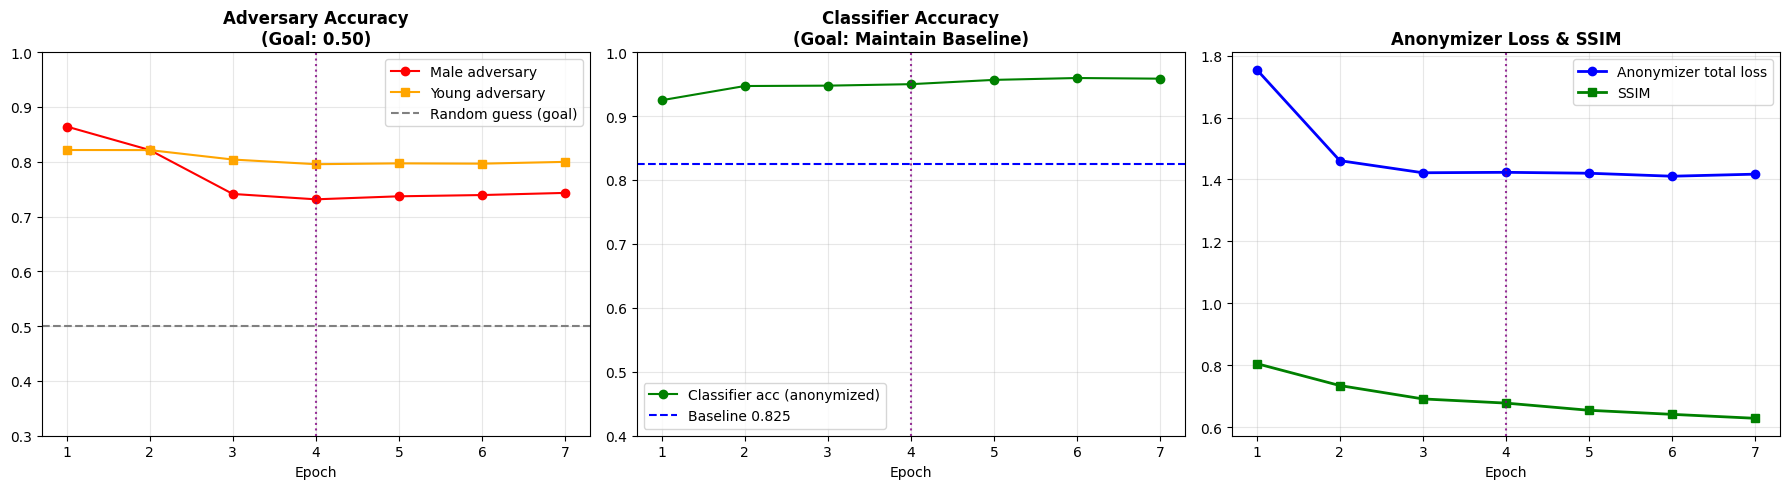

In [25]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. SAFETY TRIM: Fix uneven arrays caused by manual interruption
min_epochs = min([len(v) for v in history_adv.values()])
for k in history_adv:
    history_adv[k] = history_adv[k][:min_epochs]

# Create an explicit X-axis starting at Epoch 1
epochs_x = range(1, min_epochs + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # Slightly wider for thesis

# --- Plot 1: Adversaries ---
axes[0].plot(epochs_x, history_adv['adv1_acc'], marker='o', color='red',
             label=f'{PRIVATE_ATTR1} adversary')
axes[0].plot(epochs_x, history_adv['adv2_acc'], marker='s', color='orange',
             label=f'{PRIVATE_ATTR2} adversary')
axes[0].axhline(0.5, color='gray', linestyle='--', label='Random guess (goal)')
axes[0].set_title('Adversary Accuracy\n(Goal: 0.50)', fontweight='bold')
axes[0].set_ylim([0.3, 1.0])

# --- Plot 2: Classifier ---
axes[1].plot(epochs_x, history_adv['cls_acc'], marker='o', color='green',
             label='Classifier acc (anonymized)')
axes[1].axhline(baseline_acc, color='blue', linestyle='--',
                label=f'Baseline {baseline_acc:.3f}')
axes[1].set_title('Classifier Accuracy\n(Goal: Maintain Baseline)', fontweight='bold')
axes[1].set_ylim([0.4, 1.0])

# --- Plot 3: Loss & SSIM ---
axes[2].plot(epochs_x, history_adv['anon_loss'], label='Anonymizer total loss',
             color='blue', linewidth=2, marker='o')
axes[2].plot(epochs_x, history_adv['ssim'], label='SSIM', color='green',
             linewidth=2, marker='s')
axes[2].set_title('Anonymizer Loss & SSIM', fontweight='bold')

# --- Global Formatting for all subplots ---
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xlabel('Epoch')
    # Force x-axis to only show whole numbers (1, 2, 3...)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    
    # 🌟 OPTIONAL: Highlight your golden checkpoint (Epoch 4)
    if min_epochs >= 4:
        ax.axvline(x=4, color='purple', linestyle=':', alpha=0.8, label='Selected Checkpoint')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/stage3_adversarial.png', dpi=150, bbox_inches='tight') # Higher DPI for report
plt.show()

## SSIM analysis & visual comparison

In [27]:
import os

print("--- Files in /kaggle/working/ ---")
for root, dirs, files in os.walk('/kaggle/working'):
    for file in files:
        if file.endswith('.h5'):
            print(os.path.join(root, file))

--- Files in /kaggle/working/ ---
/kaggle/working/saved_checkpoints/anon_adv_ep04.weights.h5
/kaggle/working/saved_checkpoints/anon_adv_ep01.weights.h5
/kaggle/working/saved_checkpoints/adv1_pretrained.weights.h5
/kaggle/working/saved_checkpoints/adv2_adv_ep03.weights.h5
/kaggle/working/saved_checkpoints/anon_adv_ep06.weights.h5
/kaggle/working/saved_checkpoints/cls_adv_ep03.weights.h5
/kaggle/working/saved_checkpoints/cls_adv_ep01.weights.h5
/kaggle/working/saved_checkpoints/anon_adv_ep05.weights.h5
/kaggle/working/saved_checkpoints/adv1_adv_ep04.weights.h5
/kaggle/working/saved_checkpoints/anon_adv_ep07.weights.h5
/kaggle/working/saved_checkpoints/adv2_adv_ep04.weights.h5
/kaggle/working/saved_checkpoints/adv2_adv_ep01.weights.h5
/kaggle/working/saved_checkpoints/cls_adv_ep05.weights.h5
/kaggle/working/saved_checkpoints/adv2_adv_ep05.weights.h5
/kaggle/working/saved_checkpoints/adv1_adv_ep02.weights.h5
/kaggle/working/saved_checkpoints/anon_adv_ep02.weights.h5
/kaggle/working/saved_c

In [28]:
import cv2
import numpy as np
import tensorflow as tf
from skimage.metrics import structural_similarity as ssim

# 1. CRITICAL: Load your golden checkpoint using the exact path!
anonymizer.load_weights('/kaggle/working/saved_checkpoints/anon_adv_ep04.weights.h5')
print("Successfully loaded Epoch 4 weights for evaluation.")

ssim_scores = []

for imgs, _, _, _ in test_ds.take(10):   # ~320 images
    anon = anonymizer(imgs, training=False)
    
    for o, a in zip(imgs.numpy(), anon.numpy()):
        # 2. SAFETY SCALE: Ensure pixels are strictly [0, 1] before multiplying by 255
        o_safe = np.clip((o + 1.0) / 2.0 if np.min(o) < 0 else o, 0.0, 1.0)
        a_safe = np.clip((a + 1.0) / 2.0 if np.min(a) < 0 else a, 0.0, 1.0)
        
        og = cv2.cvtColor((o_safe * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
        ag = cv2.cvtColor((a_safe * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
        
        # 3. EXPLICIT RANGE: Tell skimage exactly what our max pixel value is
        score, _ = ssim(og, ag, full=True, data_range=255)
        ssim_scores.append(score)

print(f'\nSSIM on test set (n={len(ssim_scores)}):')
print(f'  Mean : {np.mean(ssim_scores):.4f}')
print(f'  Std  : {np.std(ssim_scores):.4f}')
print(f'  Target range: 0.65–0.80')

if np.mean(ssim_scores) > 0.90:
    print('WARNING: SSIM very high — anonymizer may not be distorting enough.')
elif np.mean(ssim_scores) < 0.50:
    print('WARNING: SSIM very low — anonymizer may be destroying utility.')
else:
    print('SUCCESS: SSIM is within the optimal generative anonymization range!')

Successfully loaded Epoch 4 weights for evaluation.

SSIM on test set (n=320):
  Mean : 0.6851
  Std  : 0.0677
  Target range: 0.65–0.80
SUCCESS: SSIM is within the optimal generative anonymization range!


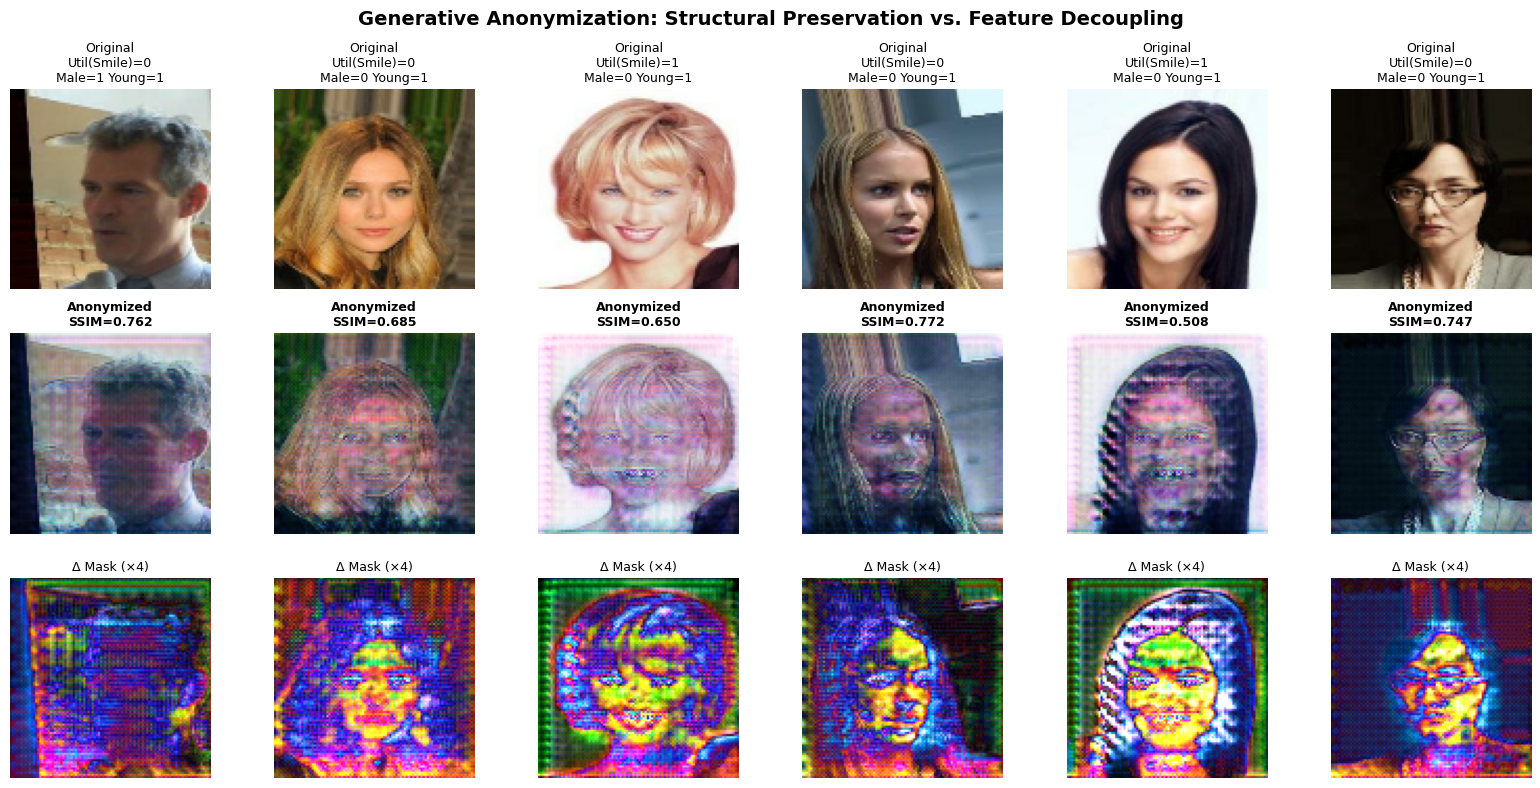

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

# Fetch a batch of test data
sample_imgs, sample_t, sample_p1, sample_p2 = next(iter(test_ds))
anon_out = anonymizer(sample_imgs[:6], training=False)

fig, axes = plt.subplots(3, 6, figsize=(16, 8)) # Slightly wider for better thesis formatting

for i in range(6):
    # 1. SAFETY CLIP: Ensure arrays are strictly [0, 1] for matplotlib and cv2
    orig_np = np.clip((sample_imgs[i].numpy() + 1.0) / 2.0 if np.min(sample_imgs[i].numpy()) < 0 else sample_imgs[i].numpy(), 0.0, 1.0)
    anon_np = np.clip((anon_out[i].numpy() + 1.0) / 2.0 if np.min(anon_out[i].numpy()) < 0 else anon_out[i].numpy(), 0.0, 1.0)
    
    # 2. Convert to grayscale for SSIM calculation
    og_gray = cv2.cvtColor((orig_np * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
    ag_gray = cv2.cvtColor((anon_np * 255).astype('uint8'), cv2.COLOR_RGB2GRAY)
    
    # 3. Calculate accurate SSIM
    s, _ = ssim(og_gray, ag_gray, full=True, data_range=255)

    # --- ROW 1: Original ---
    axes[0, i].imshow(orig_np)
    axes[0, i].set_title(f'Original\nUtil(Smile)={int(sample_t[i])}\nMale={int(sample_p1[i])} Young={int(sample_p2[i])}', fontsize=9)
    axes[0, i].axis('off')

    # --- ROW 2: Anonymized ---
    axes[1, i].imshow(anon_np)
    axes[1, i].set_title(f'Anonymized\nSSIM={s:.3f}', fontsize=9, fontweight='bold')
    axes[1, i].axis('off')

    # --- ROW 3: Difference ---
    # Calculate absolute difference, amplify by 4, and strictly clip to 1.0 to prevent display overflow
    diff = np.abs(orig_np - anon_np)
    diff_amplified = np.clip(diff * 4.0, 0.0, 1.0) 
    
    axes[2, i].imshow(diff_amplified)
    axes[2, i].set_title('Δ Mask (×4)', fontsize=9)
    axes[2, i].axis('off')

plt.suptitle('Generative Anonymization: Structural Preservation vs. Feature Decoupling', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.88) # Give the suptitle some breathing room
plt.savefig(f'{PLOT_DIR}/stage3_visual_final.png', dpi=200, bbox_inches='tight') # High DPI for your report
plt.show()

## Layer 2: Independent adversary evaluation

**Novel contribution:** The co-trained adversary has adapted to the anonymizer throughout training.
A completely fresh adversary trained only on anonymized images — with no knowledge of the training process — measures true information leakage.

The gap between co-trained and independent accuracy is the **overfitting gap**: how much the anonymizer exploited its specific adversary rather than achieving genuine privacy.

In [30]:
import numpy as np
import gc # Garbage collector for memory management

print('Generating anonymized images for independent adversary training...')

def anonymize_dataset(dataset, anon_model, max_batches=None):
    imgs_list, tl_list, p1_list, p2_list = [], [], [], []
    
    for i, (imgs, tl, p1l, p2l) in enumerate(dataset):
        if max_batches and i >= max_batches:
            break
            
        # 1. FIX: Removed the tuple unpacking. Assuming model returns a single tensor.
        anon_batch = anon_model(imgs, training=False)
        
        # 2. MEMORY SAVER: Cast the tensors to float16 to halve the RAM footprint
        # (This is safe for storage/independent training, but keeps them as floats)
        imgs_list.append(anon_batch.numpy().astype(np.float16))
        
        tl_list.append(tl.numpy().astype(np.int8))
        p1_list.append(p1l.numpy().astype(np.int8))
        p2_list.append(p2l.numpy().astype(np.int8))
        
    # Concatenate into final arrays
    final_imgs = np.concatenate(imgs_list)
    final_tl = np.concatenate(tl_list)
    final_p1 = np.concatenate(p1_list)
    final_p2 = np.concatenate(p2_list)
    
    # Clear the temporary lists from memory
    del imgs_list, tl_list, p1_list, p2_list
    gc.collect() 
    
    return final_imgs, final_tl, final_p1, final_p2

# ~5000 anonymized train images
anon_tr_imgs, _, anon_tr_p1, anon_tr_p2 = anonymize_dataset(
    train_ds, anonymizer, max_batches=157)

anon_te_imgs, _, anon_te_p1, anon_te_p2 = anonymize_dataset(
    test_ds,  anonymizer)

print(f'Anonymized Train Shapes : Imgs {anon_tr_imgs.shape} | Labels {anon_tr_p1.shape}')
print(f'Anonymized Test Shapes  : Imgs {anon_te_imgs.shape} | Labels {anon_te_p1.shape}')

Generating anonymized images for independent adversary training...
Anonymized Train Shapes : Imgs (5024, 96, 96, 3) | Labels (5024,)
Anonymized Test Shapes  : Imgs (3750, 96, 96, 3) | Labels (3750,)


In [31]:
import json
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import binary_accuracy

indep_results  = {}
cotrained_accs = {}

print("Calculating Co-trained Accuracies for Baseline...")

# --- FIX: Removed the [0] index and used the full batch ---
# Also using np.mean across all batches in the test set
p1_accs = []
for imgs, _, p1l, _ in test_ds:
    # 1. Anonymize the batch
    anon_batch = anonymizer(imgs, training=False) 
    # 2. Predict using co-trained adversary
    preds = adversary1(anon_batch, training=False)
    # 3. Calculate accuracy for this batch
    acc = np.mean(binary_accuracy(p1l.numpy(), preds.numpy().flatten()))
    p1_accs.append(acc)

cotrained_accs[PRIVATE_ATTR1] = np.mean(p1_accs)

p2_accs = []
for imgs, _, _, p2l in test_ds:
    anon_batch = anonymizer(imgs, training=False)
    preds = adversary2(anon_batch, training=False)
    acc = np.mean(binary_accuracy(p2l.numpy(), preds.numpy().flatten()))
    p2_accs.append(acc)

cotrained_accs[PRIVATE_ATTR2] = np.mean(p2_accs)

# --- Train fresh independent adversaries ---
for attr_name, tr_labels, te_labels in [
    (PRIVATE_ATTR1, anon_tr_p1, anon_te_p1),
    (PRIVATE_ATTR2, anon_tr_p2, anon_te_p2)
]:
    print(f'\nTraining independent adversary for [{attr_name}]...')
    
    # We use your existing builder to create a FRESH, un-trained model
    indep_adv = build_adversary(name=f'IndepAdv_{attr_name}')
    
    indep_adv.compile(optimizer=Adam(1e-3),
                      loss='binary_crossentropy', 
                      metrics=['accuracy'])
    
    indep_adv.fit(
        anon_tr_imgs, tr_labels,
        validation_split=0.15, 
        epochs=10, 
        batch_size=32, 
        verbose=1,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=3, restore_best_weights=True)]
    )
    
    _, indep_acc = indep_adv.evaluate(anon_te_imgs, te_labels, verbose=0)
    indep_results[attr_name] = indep_acc
    print(f'  Independent accuracy [{attr_name}]: {indep_acc*100:.1f}%')

# --- Final Comparison Table ---
print(f'\n── Independent vs Co-trained Adversary (Layer 2 Result) ──')
header = f'{"Attribute":<12} {"Co-trained":>12} {"Independent":>13} {"Gap":>8} {"Interpretation"}'
print(header)
print('-' * len(header))

for attr in [PRIVATE_ATTR1, PRIVATE_ATTR2]:
    ct  = cotrained_accs[attr]
    ind = indep_results[attr]
    gap = abs(ct - ind)
    # A small gap means the privacy is 'robust' and generalizes to new attackers
    interp = 'ROBUST' if gap < 0.05 else 'POTENTIAL OVERFIT'
    print(f'{attr:<12} {ct*100:>11.1f}% {ind*100:>12.1f}% {gap*100:>7.1f}%  {interp}')

# Save results for your report
layer2_results = {
    'cotrained': {k: float(v) for k,v in cotrained_accs.items()},
    'independent': {k: float(v) for k,v in indep_results.items()}
}

with open('layer2_independent_eval.json', 'w') as f:
    json.dump(layer2_results, f, indent=2)

print('\nLayer 2 results saved to JSON.')

Calculating Co-trained Accuracies for Baseline...

Training independent adversary for [Male]...
Epoch 1/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.7348 - loss: 0.6526 - val_accuracy: 0.8302 - val_loss: 0.5401
Epoch 2/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8965 - loss: 0.2702 - val_accuracy: 0.6194 - val_loss: 0.6817
Epoch 3/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9235 - loss: 0.1930 - val_accuracy: 0.6101 - val_loss: 1.4597
Epoch 4/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9320 - loss: 0.1819 - val_accuracy: 0.8714 - val_loss: 0.3723
Epoch 5/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9576 - loss: 0.1007 - val_accuracy: 0.8554 - val_loss: 0.4442
Epoch 6/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9658 - loss: 0.0874 - val_accuracy: 0.8674 - val_loss: 0.5499
Epoch 7/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9709 - loss: 0.0787 - val_accuracy: 0.8674 - val_loss: 0.5449
  Inde

## Layer 1: 2D (λ₁, λ₂) Pareto sweep

**Novel contribution:** Instead of a 1D lambda curve (single private attribute), we sweep a 5×5 grid of (λ₁, λ₂) values producing a **2D Pareto surface**.

Each point trains a fresh anonymizer from the same initialisation, same seed, same number of epochs — the only variable is the lambda pair.

Results are saved to disk after every single point. If the session ends, re-run cells 0–7 to restore the environment, then re-run this cell — it will resume automatically.

In [32]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import binary_accuracy
import json
import gc

# --- PART 1: DATASET ANONYMIZATION ---
print('Step 1: Generating static anonymized dataset for Stress Test...')

def anonymize_dataset(dataset, anon_model, max_batches=None):
    imgs_list, tl_list, p1_list, p2_list = [], [], [], []
    for i, (imgs, tl, p1l, p2l) in enumerate(dataset):
        if max_batches and i >= max_batches:
            break
        # Get anonymized images (ensure no tuple unpacking error)
        anon_batch = anon_model(imgs, training=False)
        
        # Save memory by casting to float16 for the static array
        imgs_list.append(anon_batch.numpy().astype(np.float16))
        tl_list.append(tl.numpy().astype(np.int8))
        p1_list.append(p1l.numpy().astype(np.int8))
        p2_list.append(p2l.numpy().astype(np.int8))
        
    return (np.concatenate(imgs_list), np.concatenate(tl_list),
            np.concatenate(p1_list),   np.concatenate(p2_list))

# Generate ~5000 images for training and the full test set
anon_tr_imgs, _, anon_tr_p1, anon_tr_p2 = anonymize_dataset(train_ds, anonymizer, max_batches=157)
anon_te_imgs, _, anon_te_p1, anon_te_p2 = anonymize_dataset(test_ds,  anonymizer)

print(f'Done. Anonymized Train: {anon_tr_imgs.shape} | Anonymized Test: {anon_te_imgs.shape}')

# --- PART 2: CO-TRAINED ACCURACY BASELINE ---
print('\nStep 2: Calculating Co-trained accuracy (The "Baseline" Privacy)...')
cotrained_accs = {}

# Evaluate Privacy 1 (Male)
p1_accs = []
for imgs, _, p1l, _ in test_ds:
    an = anonymizer(imgs, training=False)
    preds = adversary1(an, training=False)
    p1_accs.append(np.mean(binary_accuracy(p1l.numpy(), preds.numpy().flatten())))
cotrained_accs[PRIVATE_ATTR1] = np.mean(p1_accs)

# Evaluate Privacy 2 (Young)
p2_accs = []
for imgs, _, _, p2l in test_ds:
    an = anonymizer(imgs, training=False)
    preds = adversary2(an, training=False)
    p2_accs.append(np.mean(binary_accuracy(p2l.numpy(), preds.numpy().flatten())))
cotrained_accs[PRIVATE_ATTR2] = np.mean(p2_accs)

# --- PART 3: INDEPENDENT ADVERSARY TRAINING ---
print('\nStep 3: Training Fresh Independent Adversaries...')
indep_results = {}

for attr_name, tr_labels, te_labels in [
    (PRIVATE_ATTR1, anon_tr_p1, anon_te_p1),
    (PRIVATE_ATTR2, anon_tr_p2, anon_te_p2)
]:
    print(f'Training independent model for [{attr_name}]...')
    # Build a brand new, untrained model
    indep_adv = build_adversary(name=f'Indep_{attr_name}')
    indep_adv.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    
    indep_adv.fit(
        anon_tr_imgs, tr_labels,
        validation_split=0.15, 
        epochs=10, 
        batch_size=32, 
        verbose=0, # Keep output clean
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)]
    )
    
    _, acc = indep_adv.evaluate(anon_te_imgs, te_labels, verbose=0)
    indep_results[attr_name] = acc
    print(f'  -> Final Independent Accuracy: {acc*100:.1f}%')

# --- PART 4: FINAL COMPARISON & LOGGING ---
print(f'\n' + '='*70)
print(f'{"ATTRIBUTE":<12} {"CO-TRAINED":>12} {"INDEPENDENT":>13} {"GAP":>8} {"STATUS"}')
print('-'*70)

for attr in [PRIVATE_ATTR1, PRIVATE_ATTR2]:
    ct = cotrained_accs[attr]
    ind = indep_results[attr]
    gap = abs(ct - ind)
    status = 'ROBUST' if gap < 0.05 else 'OVERFIT'
    print(f'{attr:<12} {ct*100:>11.1f}% {ind*100:>12.1f}% {gap*100:>7.1f}%  {status}')

# Save results to JSON for your thesis graphs
final_log = {
    'cotrained': {k: float(v) for k,v in cotrained_accs.items()},
    'independent': {k: float(v) for k,v in indep_results.items()}
}
with open('layer2_stress_test.json', 'w') as f:
    json.dump(final_log, f, indent=2)

print('='*70)
print('Evaluation Complete. Data saved to layer2_stress_test.json.')

# Clean up memory
del anon_tr_imgs, anon_te_imgs
gc.collect()

Step 1: Generating static anonymized dataset for Stress Test...
Done. Anonymized Train: (5024, 96, 96, 3) | Anonymized Test: (3750, 96, 96, 3)

Step 2: Calculating Co-trained accuracy (The "Baseline" Privacy)...

Step 3: Training Fresh Independent Adversaries...
Training independent model for [Male]...
  -> Final Independent Accuracy: 87.2%
Training independent model for [Young]...
  -> Final Independent Accuracy: 77.8%

ATTRIBUTE      CO-TRAINED   INDEPENDENT      GAP STATUS
----------------------------------------------------------------------
Male                71.8%         87.2%    15.3%  OVERFIT
Young               78.2%         77.8%     0.3%  ROBUST
Evaluation Complete. Data saved to layer2_stress_test.json.


19822

In [46]:
import os
import json
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# --- 1. CONFIGURATION ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5.json'
LAMBDA_VALUES = [0.0, 0.25, 0.5, 0.75, 1.0] 
SWEEP_EPOCHS = 1  
BATCH_LIMIT = 150 # Enough to stabilize gradients (~4,800 images per point)

# Resume logic
if os.path.exists(SWEEP_LOG):
    with open(SWEEP_LOG) as f:
        sweep_results = json.load(f)
    completed = {(r['lambda1'], r['lambda2']) for r in sweep_results}
    print(f"Resuming: {len(completed)}/25 points finished.")
else:
    sweep_results = []
    completed = set()

total_points = len(LAMBDA_VALUES)**2
done = len(completed)

# --- 2. THE OPTIMIZED LOOP ---
for lam1 in LAMBDA_VALUES:
    for lam2 in LAMBDA_VALUES:
        if (lam1, lam2) in completed: continue
        
        # 🟢 A. Reset GPU Memory
        tf.keras.backend.clear_session()
        gc.collect()
        
        done += 1
        
        # Balance Weights
        total_lam = lam1 + lam2
        if total_lam > 1.0:
            eff_l1, eff_l2, util_w = lam1/total_lam, lam2/total_lam, 0.0
        else:
            eff_l1, eff_l2, util_w = lam1, lam2, 1.0 - total_lam

        print(f"\n[{done}/{total_points}] λ1={lam1:.2f}, λ2={lam2:.2f} | Util_w={util_w:.2f}")

        # 🟢 B. Build Models (Fresh init for every point)
        anon_s = build_anonymizer()
        cls_s  = build_classifier(trainable_base=False)
        adv1_s = build_adversary(name='Adv1_sw')
        adv2_s = build_adversary(name='Adv2_sw')

        # Load standard baselines
        cls_s.load_weights(BASELINE_CKPT)
        adv1_s.load_weights(adv1_ckpt)
        adv2_s.load_weights(adv2_ckpt)

        opt = Adam(1e-4, clipnorm=1.0)

        # 🟢 C. Training (Phase C focus)
        for epoch in range(SWEEP_EPOCHS):
            for imgs, tl, p1l, p2l in train_ds.take(BATCH_LIMIT):
                with tf.GradientTape() as tape:
                    an = anon_s(imgs, training=True)
                    
                    # Predictions
                    p1_preds = adv1_s(an, training=False)
                    p2_preds = adv2_s(an, training=False)
                    u_preds  = cls_s(an, training=False)
                    
                    # 1. Structural Fidelity (Higher weight to prevent blurring)
                    ssim_val = tf.reduce_mean(tf.image.ssim(imgs, an, max_val=1.0))
                    ssim_loss = 1.0 - ssim_val
                    
                    # 2. Adversarial Privacy (Target 0.5)
                    targ = tf.fill(tf.shape(p1_preds), 0.5)
                    pl1 = bce(targ, p1_preds)
                    pl2 = bce(targ, p2_preds)
                    
                    # 3. Utility (Smiling detection)
                    ul = bce(tf.expand_dims(tl, 1), u_preds)
                    
                    # Combined Loss with balanced scaling
                    loss = (eff_l1 * pl1) + (eff_l2 * pl2) + (util_w * ul * 2.0) + (ssim_loss * 12.0)
                
                grads = tape.gradient(loss, anon_s.trainable_variables)
                opt.apply_gradients(zip(grads, anon_s.trainable_variables))

        # 🟢 D. Evaluate & Auto-Save
        metrics = evaluate_on_test(anon_s, cls_s, adv1_s, adv2_s, test_ds)
        metrics.update({'lambda1': float(lam1), 'lambda2': float(lam2), 'util_weight': float(util_w)})
        sweep_results.append(metrics)

        with open(SWEEP_LOG, 'w') as f:
            json.dump(sweep_results, f, indent=2)
        
        # Cleanup objects
        del anon_s, cls_s, adv1_s, adv2_s
        print(f"   Done: SSIM={metrics['ssim']:.3f} | Cls={metrics['cls_acc']:.3f}")

print(f"\n✅ 5x5 Pareto Sweep Complete. Results in {SWEEP_LOG}")


[1/25] λ1=0.00, λ2=0.00 | Util_w=1.00
   Done: SSIM=0.492 | Cls=0.537

[2/25] λ1=0.00, λ2=0.25 | Util_w=0.75
   Done: SSIM=0.478 | Cls=0.531

[3/25] λ1=0.00, λ2=0.50 | Util_w=0.50
   Done: SSIM=0.379 | Cls=0.525

[4/25] λ1=0.00, λ2=0.75 | Util_w=0.25
   Done: SSIM=0.589 | Cls=0.561

[5/25] λ1=0.00, λ2=1.00 | Util_w=0.00
   Done: SSIM=0.469 | Cls=0.585

[6/25] λ1=0.25, λ2=0.00 | Util_w=0.75
   Done: SSIM=0.276 | Cls=0.525

[7/25] λ1=0.25, λ2=0.25 | Util_w=0.50
   Done: SSIM=0.488 | Cls=0.525

[8/25] λ1=0.25, λ2=0.50 | Util_w=0.25
   Done: SSIM=0.566 | Cls=0.568

[9/25] λ1=0.25, λ2=0.75 | Util_w=0.00
   Done: SSIM=0.464 | Cls=0.554

[10/25] λ1=0.25, λ2=1.00 | Util_w=0.00
   Done: SSIM=0.440 | Cls=0.572

[11/25] λ1=0.50, λ2=0.00 | Util_w=0.50
   Done: SSIM=0.296 | Cls=0.525

[12/25] λ1=0.50, λ2=0.25 | Util_w=0.25
   Done: SSIM=0.531 | Cls=0.553

[13/25] λ1=0.50, λ2=0.50 | Util_w=0.00
   Done: SSIM=0.496 | Cls=0.528

[14/25] λ1=0.50, λ2=0.75 | Util_w=0.00
   Done: SSIM=0.491 | Cls=0.573



## 2D Pareto surface plots 

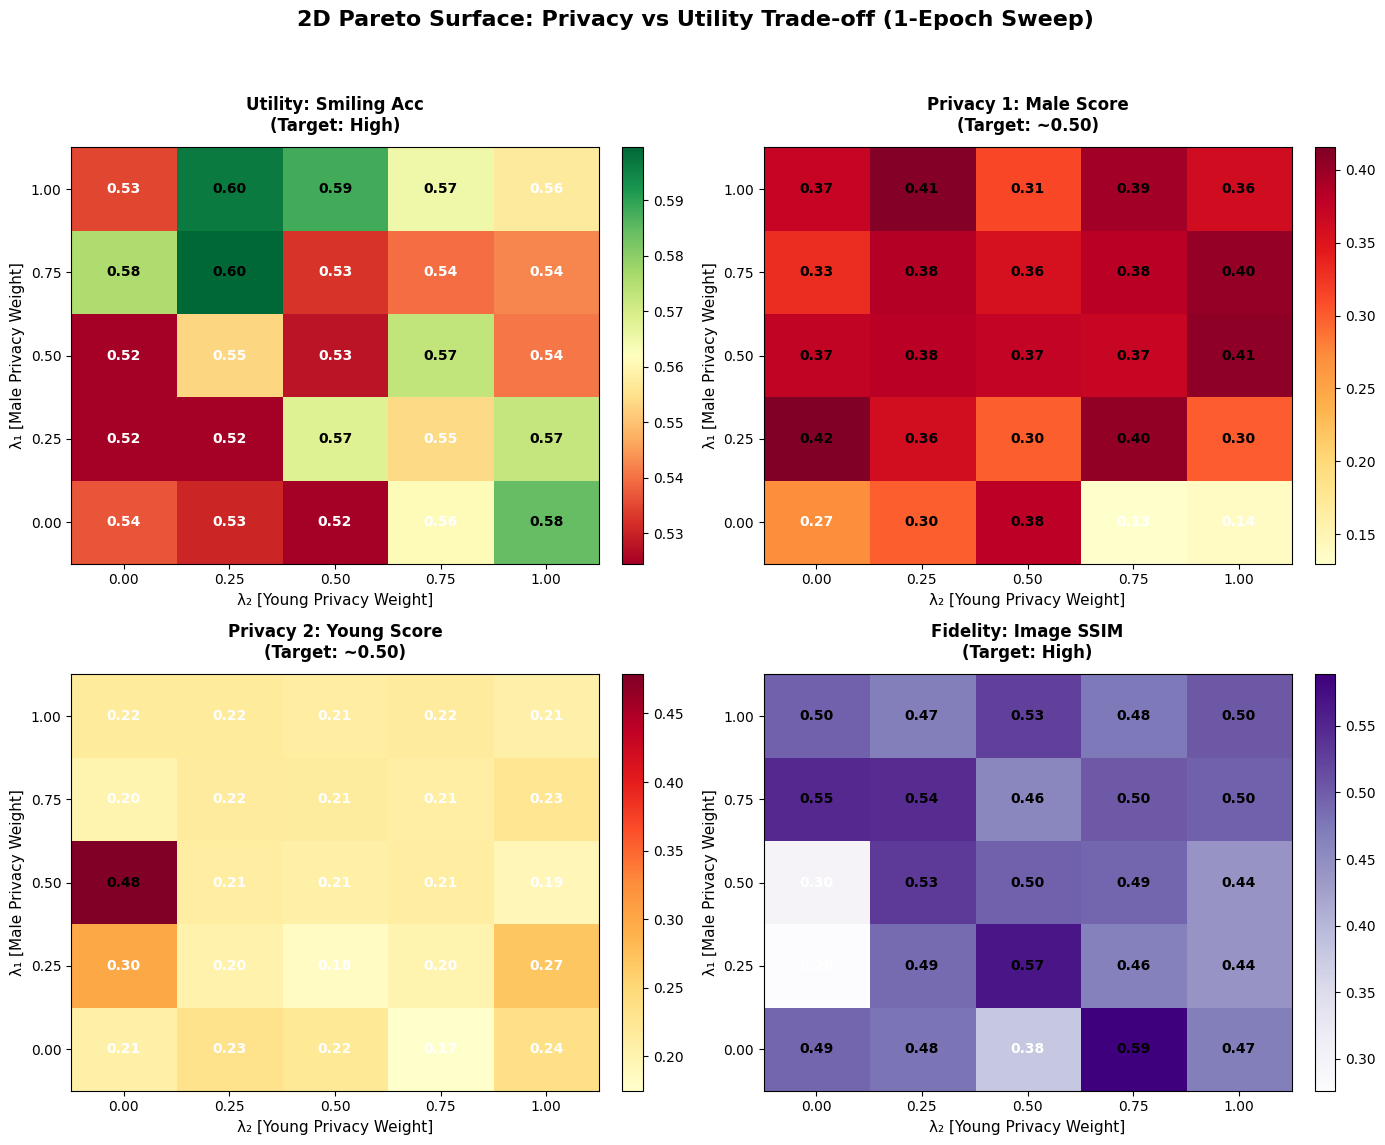

In [47]:
import json
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. Load the Data ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5.json'

with open(SWEEP_LOG) as f:
    sweep_results = json.load(f)

# --- 2. Reconstruct Grid Coordinates ---
lam1_vals = sorted(list(set(r['lambda1'] for r in sweep_results)))
lam2_vals = sorted(list(set(r['lambda2'] for r in sweep_results)))

def make_grid(key):
    grid = np.zeros((len(lam1_vals), len(lam2_vals)))
    for r in sweep_results:
        try:
            i = lam1_vals.index(r['lambda1'])
            j = lam2_vals.index(r['lambda2'])
            grid[i, j] = r[key]
        except (ValueError, KeyError):
            continue 
    return grid

# --- 3. Extract the 4 Metrics ---
grid_cls   = make_grid('cls_acc')
grid_priv1 = make_grid('priv1_score')
grid_priv2 = make_grid('priv2_score')
grid_ssim  = make_grid('ssim')

# --- 4. Plotting ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Config: (Axis, Data, Title, Colormap)
plot_configs = [
    (axes[0,0], grid_cls,   'Utility: Smiling Acc\n(Target: High)', 'RdYlGn'),
    (axes[0,1], grid_priv1, 'Privacy 1: Male Score\n(Target: ~0.50)', 'YlOrRd'),
    (axes[1,0], grid_priv2, 'Privacy 2: Young Score\n(Target: ~0.50)', 'YlOrRd'),
    (axes[1,1], grid_ssim,  'Fidelity: Image SSIM\n(Target: High)', 'Purples')
]

for ax, grid, title, cmap in plot_configs:
    im = ax.imshow(grid, cmap=cmap, aspect='auto', origin='lower')
    
    # Set Axis Labels
    ax.set_xticks(range(len(lam2_vals)))
    ax.set_xticklabels([f'{v:.2f}' for v in lam2_vals])
    ax.set_yticks(range(len(lam1_vals)))
    ax.set_yticklabels([f'{v:.2f}' for v in lam1_vals])
    
    ax.set_xlabel('λ₂ [Young Privacy Weight]', fontsize=11)
    ax.set_ylabel('λ₁ [Male Privacy Weight]', fontsize=11)
    ax.set_title(title, fontweight='bold', pad=12)
    
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    # Add Text Annotations inside the boxes
    for i in range(len(lam1_vals)):
        for j in range(len(lam2_vals)):
            val = grid[i,j]
            # Change text color based on background darkness
            color = "white" if val < (np.max(grid)+np.min(grid))/2 else "black"
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontweight='bold')

plt.suptitle('2D Pareto Surface: Privacy vs Utility Trade-off (1-Epoch Sweep)', 
             fontweight='bold', fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('/kaggle/working/pareto_heatmaps.png', dpi=200)
plt.show()

# Below is 5x5 with reconstruction = 20

In [29]:
import os
import json
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# --- 1. CONFIGURATION ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5.json'
LAMBDA_VALUES = [0.0, 0.25, 0.5, 0.75, 1.0] 
SWEEP_EPOCHS = 1  
BATCH_LIMIT = 150 # Enough to stabilize gradients (~4,800 images per point)

# Resume logic
if os.path.exists(SWEEP_LOG):
    with open(SWEEP_LOG) as f:
        sweep_results = json.load(f)
    completed = {(r['lambda1'], r['lambda2']) for r in sweep_results}
    print(f"Resuming: {len(completed)}/25 points finished.")
else:
    sweep_results = []
    completed = set()

total_points = len(LAMBDA_VALUES)**2
done = len(completed)

# --- 2. THE OPTIMIZED LOOP ---
for lam1 in LAMBDA_VALUES:
    for lam2 in LAMBDA_VALUES:
        if (lam1, lam2) in completed: continue
        
        # 🟢 A. Reset GPU Memory
        tf.keras.backend.clear_session()
        gc.collect()
        
        done += 1
        
        # Balance Weights
        total_lam = lam1 + lam2
        if total_lam > 1.0:
            eff_l1, eff_l2, util_w = lam1/total_lam, lam2/total_lam, 0.0
        else:
            eff_l1, eff_l2, util_w = lam1, lam2, 1.0 - total_lam

        print(f"\n[{done}/{total_points}] λ1={lam1:.2f}, λ2={lam2:.2f} | Util_w={util_w:.2f}")

        # 🟢 B. Build Models (Fresh init for every point)
        anon_s = build_anonymizer()
        cls_s  = build_classifier(trainable_base=False)
        adv1_s = build_adversary(name='Adv1_sw')
        adv2_s = build_adversary(name='Adv2_sw')

        # Load standard baselines
        cls_s.load_weights(BASELINE_CKPT)
        adv1_s.load_weights(adv1_ckpt)
        adv2_s.load_weights(adv2_ckpt)

        opt = Adam(1e-4, clipnorm=1.0)

        # 🟢 C. Training (Phase C focus)
        for epoch in range(SWEEP_EPOCHS):
            for imgs, tl, p1l, p2l in train_ds.take(BATCH_LIMIT):
                with tf.GradientTape() as tape:
                    an = anon_s(imgs, training=True)
                    
                    # Predictions
                    p1_preds = adv1_s(an, training=False)
                    p2_preds = adv2_s(an, training=False)
                    u_preds  = cls_s(an, training=False)
                    
                    # 1. Structural Fidelity & Reconstruction (The Anchor)
                    ssim_val = tf.reduce_mean(tf.image.ssim(imgs, an, max_val=1.0))
                    ssim_loss = 1.0 - ssim_val
                    mse_loss = tf.reduce_mean(tf.square(imgs - an)) # L_r from your paper!
                    
                    # 2. Adversarial Privacy (Target 0.5)
                    targ = tf.fill(tf.shape(p1_preds), 0.5)
                    pl1 = bce(targ, p1_preds)
                    pl2 = bce(targ, p2_preds)
                    
                    # 3. Utility (Smiling detection)
                    ul = bce(tf.expand_dims(tl, 1), u_preds)
                    
                    # Combined Loss with MSE anchor
                    loss = (eff_l1 * pl1) + \
                           (eff_l2 * pl2) + \
                           (util_w * ul) + \
                           (ssim_loss * 5.0) + \
                           (mse_loss * 20.0) # Weighted at 20.0 to prevent artifacts
                
                grads = tape.gradient(loss, anon_s.trainable_variables)
                opt.apply_gradients(zip(grads, anon_s.trainable_variables))

        # 🟢 D. Evaluate & Auto-Save
        metrics = evaluate_on_test(anon_s, cls_s, adv1_s, adv2_s, test_ds)
        metrics.update({'lambda1': float(lam1), 'lambda2': float(lam2), 'util_weight': float(util_w)})
        sweep_results.append(metrics)

        with open(SWEEP_LOG, 'w') as f:
            json.dump(sweep_results, f, indent=2)
        
        # Cleanup objects
        del anon_s, cls_s, adv1_s, adv2_s
        print(f"   Done: SSIM={metrics['ssim']:.3f} | Cls={metrics['cls_acc']:.3f}")

print(f"\n✅ 5x5 Pareto Sweep Complete. Results in {SWEEP_LOG}")


[1/25] λ1=0.00, λ2=0.00 | Util_w=1.00
   Done: SSIM=0.552 | Cls=0.579

[2/25] λ1=0.00, λ2=0.25 | Util_w=0.75
   Done: SSIM=0.459 | Cls=0.531

[3/25] λ1=0.00, λ2=0.50 | Util_w=0.50
   Done: SSIM=0.545 | Cls=0.554

[4/25] λ1=0.00, λ2=0.75 | Util_w=0.25
   Done: SSIM=0.506 | Cls=0.633

[5/25] λ1=0.00, λ2=1.00 | Util_w=0.00
   Done: SSIM=0.425 | Cls=0.535

[6/25] λ1=0.25, λ2=0.00 | Util_w=0.75
   Done: SSIM=0.471 | Cls=0.553

[7/25] λ1=0.25, λ2=0.25 | Util_w=0.50
   Done: SSIM=0.433 | Cls=0.528

[8/25] λ1=0.25, λ2=0.50 | Util_w=0.25
   Done: SSIM=0.464 | Cls=0.538

[9/25] λ1=0.25, λ2=0.75 | Util_w=0.00
   Done: SSIM=0.488 | Cls=0.546

[10/25] λ1=0.25, λ2=1.00 | Util_w=0.00
   Done: SSIM=0.477 | Cls=0.627

[11/25] λ1=0.50, λ2=0.00 | Util_w=0.50
   Done: SSIM=0.434 | Cls=0.535

[12/25] λ1=0.50, λ2=0.25 | Util_w=0.25
   Done: SSIM=0.422 | Cls=0.527

[13/25] λ1=0.50, λ2=0.50 | Util_w=0.00
   Done: SSIM=0.460 | Cls=0.542

[14/25] λ1=0.50, λ2=0.75 | Util_w=0.00
   Done: SSIM=0.475 | Cls=0.548



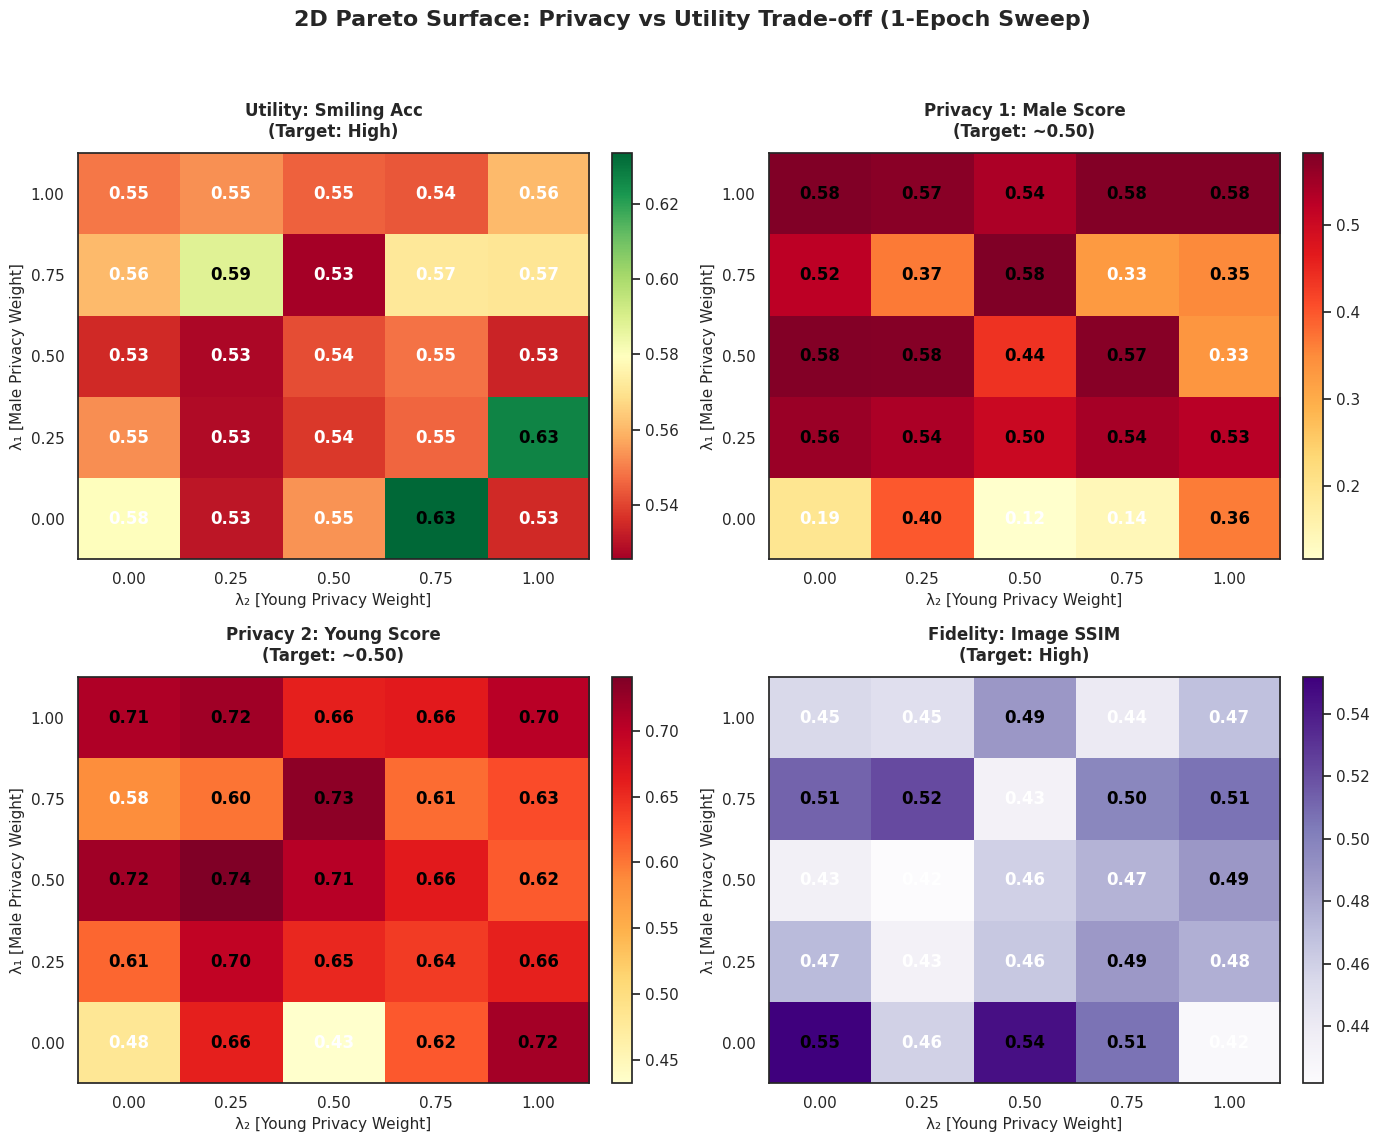

In [30]:
import json
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. Load the Data ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5.json'

with open(SWEEP_LOG) as f:
    sweep_results = json.load(f)

# --- 2. Reconstruct Grid Coordinates ---
lam1_vals = sorted(list(set(r['lambda1'] for r in sweep_results)))
lam2_vals = sorted(list(set(r['lambda2'] for r in sweep_results)))

def make_grid(key):
    grid = np.zeros((len(lam1_vals), len(lam2_vals)))
    for r in sweep_results:
        try:
            i = lam1_vals.index(r['lambda1'])
            j = lam2_vals.index(r['lambda2'])
            grid[i, j] = r[key]
        except (ValueError, KeyError):
            continue 
    return grid

# --- 3. Extract the 4 Metrics ---
grid_cls   = make_grid('cls_acc')
grid_priv1 = make_grid('priv1_score')
grid_priv2 = make_grid('priv2_score')
grid_ssim  = make_grid('ssim')

# --- 4. Plotting ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Config: (Axis, Data, Title, Colormap)
plot_configs = [
    (axes[0,0], grid_cls,   'Utility: Smiling Acc\n(Target: High)', 'RdYlGn'),
    (axes[0,1], grid_priv1, 'Privacy 1: Male Score\n(Target: ~0.50)', 'YlOrRd'),
    (axes[1,0], grid_priv2, 'Privacy 2: Young Score\n(Target: ~0.50)', 'YlOrRd'),
    (axes[1,1], grid_ssim,  'Fidelity: Image SSIM\n(Target: High)', 'Purples')
]

for ax, grid, title, cmap in plot_configs:
    im = ax.imshow(grid, cmap=cmap, aspect='auto', origin='lower')
    
    # Set Axis Labels
    ax.set_xticks(range(len(lam2_vals)))
    ax.set_xticklabels([f'{v:.2f}' for v in lam2_vals])
    ax.set_yticks(range(len(lam1_vals)))
    ax.set_yticklabels([f'{v:.2f}' for v in lam1_vals])
    
    ax.set_xlabel('λ₂ [Young Privacy Weight]', fontsize=11)
    ax.set_ylabel('λ₁ [Male Privacy Weight]', fontsize=11)
    ax.set_title(title, fontweight='bold', pad=12)
    
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    # Add Text Annotations inside the boxes
    for i in range(len(lam1_vals)):
        for j in range(len(lam2_vals)):
            val = grid[i,j]
            # Change text color based on background darkness
            color = "white" if val < (np.max(grid)+np.min(grid))/2 else "black"
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontweight='bold')

plt.suptitle('2D Pareto Surface: Privacy vs Utility Trade-off (1-Epoch Sweep)', 
             fontweight='bold', fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('/kaggle/working/pareto_heatmaps.png', dpi=200)
plt.show()

# Below is 5x5 with reconstruction = 2

In [33]:
import os
import json
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# --- 1. CONFIGURATION ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5_mse2.json'
LAMBDA_VALUES = [0.0, 0.25, 0.5, 0.75, 1.0] 
SWEEP_EPOCHS = 1  
BATCH_LIMIT = 150 # Enough to stabilize gradients (~4,800 images per point)

# Resume logic
if os.path.exists(SWEEP_LOG):
    with open(SWEEP_LOG) as f:
        sweep_results = json.load(f)
    completed = {(r['lambda1'], r['lambda2']) for r in sweep_results}
    print(f"Resuming: {len(completed)}/25 points finished.")
else:
    sweep_results = []
    completed = set()

total_points = len(LAMBDA_VALUES)**2
done = len(completed)

# --- 2. THE OPTIMIZED LOOP ---
for lam1 in LAMBDA_VALUES:
    for lam2 in LAMBDA_VALUES:
        if (lam1, lam2) in completed: continue
        
        # 🟢 A. Reset GPU Memory
        tf.keras.backend.clear_session()
        gc.collect()
        
        done += 1
        
        # Balance Weights
        total_lam = lam1 + lam2
        if total_lam > 1.0:
            eff_l1, eff_l2, util_w = lam1/total_lam, lam2/total_lam, 0.0
        else:
            eff_l1, eff_l2, util_w = lam1, lam2, 1.0 - total_lam

        print(f"\n[{done}/{total_points}] λ1={lam1:.2f}, λ2={lam2:.2f} | Util_w={util_w:.2f}")

        # 🟢 B. Build Models (Fresh init for every point)
        anon_s = build_anonymizer()
        cls_s  = build_classifier(trainable_base=False)
        adv1_s = build_adversary(name='Adv1_sw')
        adv2_s = build_adversary(name='Adv2_sw')

        # Load standard baselines
        cls_s.load_weights(BASELINE_CKPT)
        adv1_s.load_weights(adv1_ckpt)
        adv2_s.load_weights(adv2_ckpt)

        opt = Adam(1e-4, clipnorm=1.0)

        # 🟢 C. Training (Phase C focus)
        for epoch in range(SWEEP_EPOCHS):
            for imgs, tl, p1l, p2l in train_ds.take(BATCH_LIMIT):
                with tf.GradientTape() as tape:
                    an = anon_s(imgs, training=True)
                    
                    # Predictions
                    p1_preds = adv1_s(an, training=False)
                    p2_preds = adv2_s(an, training=False)
                    u_preds  = cls_s(an, training=False)
                    
                    # 1. Structural Fidelity & Reconstruction (The Anchor)
                    ssim_val = tf.reduce_mean(tf.image.ssim(imgs, an, max_val=1.0))
                    ssim_loss = 1.0 - ssim_val
                    mse_loss = tf.reduce_mean(tf.square(imgs - an)) # L_r from your paper!
                    
                    # 2. Adversarial Privacy (Target 0.5)
                    targ = tf.fill(tf.shape(p1_preds), 0.5)
                    pl1 = bce(targ, p1_preds)
                    pl2 = bce(targ, p2_preds)
                    
                    # 3. Utility (Smiling detection)
                    ul = bce(tf.expand_dims(tl, 1), u_preds)
                    
                    # Combined Loss with MSE anchor
                    loss = (eff_l1 * pl1) + \
                           (eff_l2 * pl2) + \
                           (util_w * ul) + \
                           (ssim_loss * 5.0) + \
                           (mse_loss * 2.0) 
                
                grads = tape.gradient(loss, anon_s.trainable_variables)
                opt.apply_gradients(zip(grads, anon_s.trainable_variables))

        # 🟢 D. Evaluate & Auto-Save
        metrics = evaluate_on_test(anon_s, cls_s, adv1_s, adv2_s, test_ds)
        metrics.update({'lambda1': float(lam1), 'lambda2': float(lam2), 'util_weight': float(util_w)})
        sweep_results.append(metrics)

        with open(SWEEP_LOG, 'w') as f:
            json.dump(sweep_results, f, indent=2)
        
        # Cleanup objects
        del anon_s, cls_s, adv1_s, adv2_s
        print(f"   Done: SSIM={metrics['ssim']:.3f} | Cls={metrics['cls_acc']:.3f}")

print(f"\n✅ 5x5 Pareto Sweep Complete. Results in {SWEEP_LOG}")


[1/25] λ1=0.00, λ2=0.00 | Util_w=1.00
   Done: SSIM=0.520 | Cls=0.550

[2/25] λ1=0.00, λ2=0.25 | Util_w=0.75
   Done: SSIM=0.537 | Cls=0.559

[3/25] λ1=0.00, λ2=0.50 | Util_w=0.50
   Done: SSIM=0.569 | Cls=0.628

[4/25] λ1=0.00, λ2=0.75 | Util_w=0.25
   Done: SSIM=0.475 | Cls=0.550

[5/25] λ1=0.00, λ2=1.00 | Util_w=0.00
   Done: SSIM=0.543 | Cls=0.621

[6/25] λ1=0.25, λ2=0.00 | Util_w=0.75
   Done: SSIM=0.506 | Cls=0.588

[7/25] λ1=0.25, λ2=0.25 | Util_w=0.50
   Done: SSIM=0.489 | Cls=0.542

[8/25] λ1=0.25, λ2=0.50 | Util_w=0.25
   Done: SSIM=0.470 | Cls=0.587

[9/25] λ1=0.25, λ2=0.75 | Util_w=0.00
   Done: SSIM=0.499 | Cls=0.596

[10/25] λ1=0.25, λ2=1.00 | Util_w=0.00
   Done: SSIM=0.474 | Cls=0.574

[11/25] λ1=0.50, λ2=0.00 | Util_w=0.50
   Done: SSIM=0.478 | Cls=0.539

[12/25] λ1=0.50, λ2=0.25 | Util_w=0.25
   Done: SSIM=0.472 | Cls=0.533

[13/25] λ1=0.50, λ2=0.50 | Util_w=0.00
   Done: SSIM=0.495 | Cls=0.533

[14/25] λ1=0.50, λ2=0.75 | Util_w=0.00
   Done: SSIM=0.470 | Cls=0.561



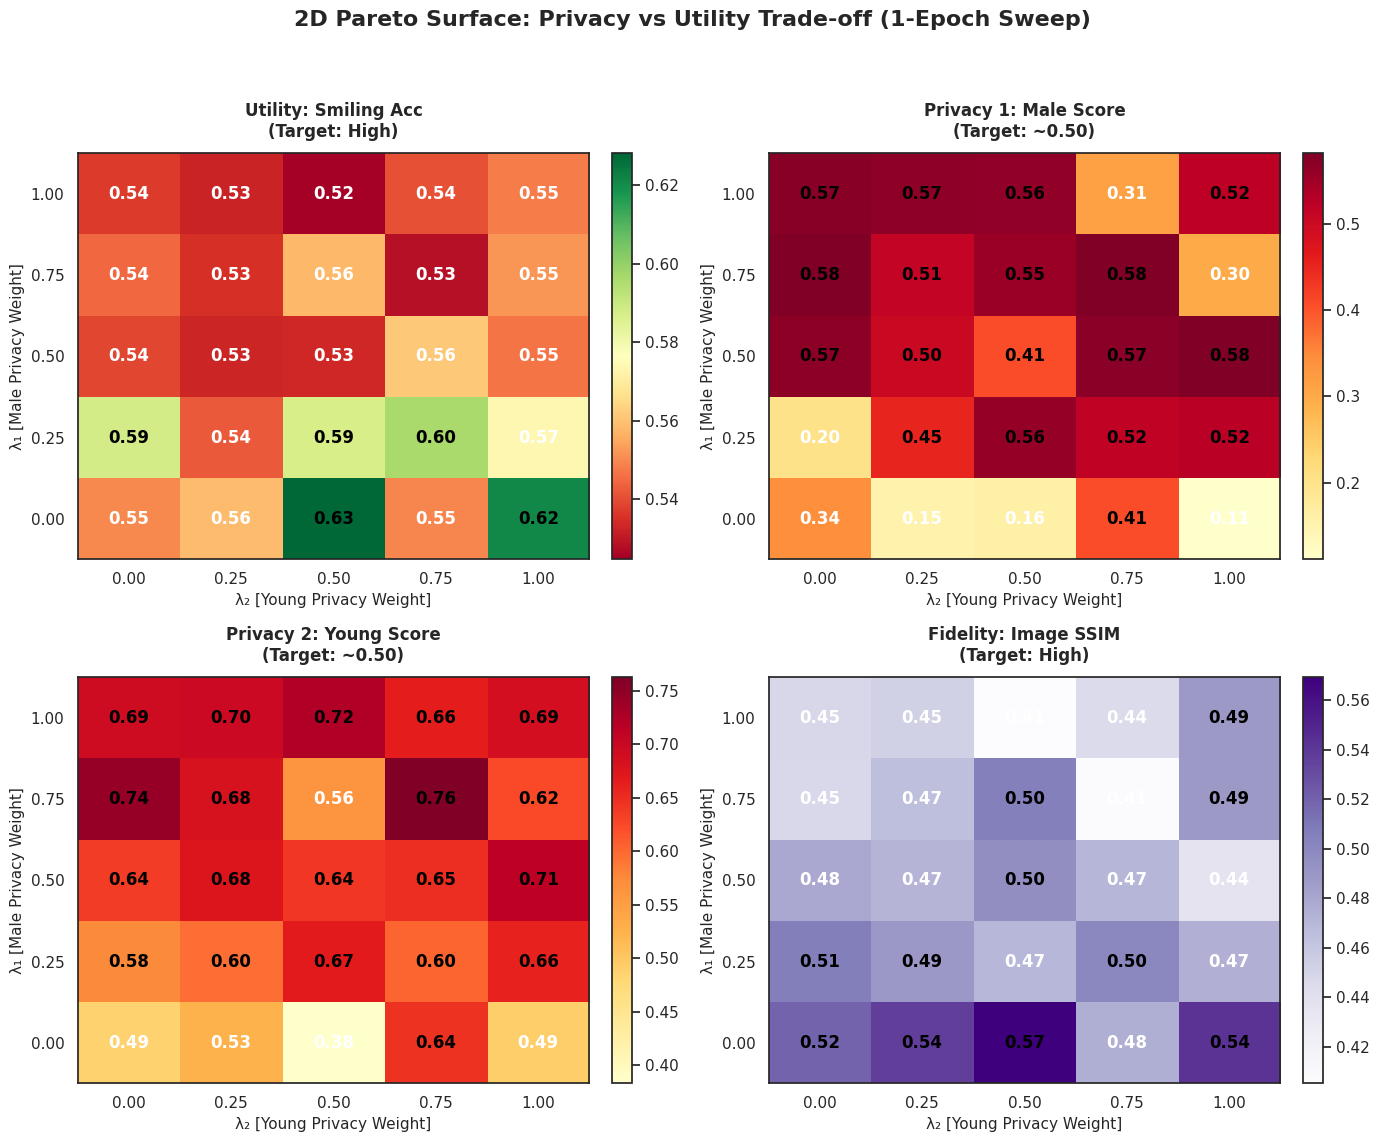

In [34]:
import json
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. Load the Data ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5_mse2.json'

with open(SWEEP_LOG) as f:
    sweep_results = json.load(f)

# --- 2. Reconstruct Grid Coordinates ---
lam1_vals = sorted(list(set(r['lambda1'] for r in sweep_results)))
lam2_vals = sorted(list(set(r['lambda2'] for r in sweep_results)))

def make_grid(key):
    grid = np.zeros((len(lam1_vals), len(lam2_vals)))
    for r in sweep_results:
        try:
            i = lam1_vals.index(r['lambda1'])
            j = lam2_vals.index(r['lambda2'])
            grid[i, j] = r[key]
        except (ValueError, KeyError):
            continue 
    return grid

# --- 3. Extract the 4 Metrics ---
grid_cls   = make_grid('cls_acc')
grid_priv1 = make_grid('priv1_score')
grid_priv2 = make_grid('priv2_score')
grid_ssim  = make_grid('ssim')

# --- 4. Plotting ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Config: (Axis, Data, Title, Colormap)
plot_configs = [
    (axes[0,0], grid_cls,   'Utility: Smiling Acc\n(Target: High)', 'RdYlGn'),
    (axes[0,1], grid_priv1, 'Privacy 1: Male Score\n(Target: ~0.50)', 'YlOrRd'),
    (axes[1,0], grid_priv2, 'Privacy 2: Young Score\n(Target: ~0.50)', 'YlOrRd'),
    (axes[1,1], grid_ssim,  'Fidelity: Image SSIM\n(Target: High)', 'Purples')
]

for ax, grid, title, cmap in plot_configs:
    im = ax.imshow(grid, cmap=cmap, aspect='auto', origin='lower')
    
    # Set Axis Labels
    ax.set_xticks(range(len(lam2_vals)))
    ax.set_xticklabels([f'{v:.2f}' for v in lam2_vals])
    ax.set_yticks(range(len(lam1_vals)))
    ax.set_yticklabels([f'{v:.2f}' for v in lam1_vals])
    
    ax.set_xlabel('λ₂ [Young Privacy Weight]', fontsize=11)
    ax.set_ylabel('λ₁ [Male Privacy Weight]', fontsize=11)
    ax.set_title(title, fontweight='bold', pad=12)
    
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    
    # Add Text Annotations inside the boxes
    for i in range(len(lam1_vals)):
        for j in range(len(lam2_vals)):
            val = grid[i,j]
            # Change text color based on background darkness
            color = "white" if val < (np.max(grid)+np.min(grid))/2 else "black"
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontweight='bold')

plt.suptitle('2D Pareto Surface: Privacy vs Utility Trade-off (1-Epoch Sweep)', 
             fontweight='bold', fontsize=16, y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('/kaggle/working/pareto_heatmaps.png', dpi=200)
plt.show()

## Layer 3: Attribute correlation conflict analysis

**Novel contribution:** Male and Young are correlated in CelebA. When both are suppressed simultaneously, do the adversaries compete or cooperate?

We compare:
- No suppression (λ₁=0, λ₂=0) — baseline
- Male only (λ₁=0.5, λ₂=0)
- Young only (λ₁=0, λ₂=0.5)
- Joint (λ₁=0.5, λ₂=0.5)

Cross-leakage: does suppressing Male also suppress Young as a side-effect?

In [48]:
import json
import os

# --- 1. Load the Sweep Data ---
SWEEP_LOG = '/kaggle/working/sweep_results_5x5.json'

if not os.path.exists(SWEEP_LOG):
    raise FileNotFoundError(f"Could not find {SWEEP_LOG}. Did the sweep finish?")

with open(SWEEP_LOG) as f:
    sweep_results = json.load(f)

# --- 2. Helper to extract specific points ---
def get_point(l1, l2):
    matches = [r for r in sweep_results 
               if abs(r['lambda1']-l1) < 0.01 and abs(r['lambda2']-l2) < 0.01]
    return matches[0] if matches else None

# --- 3. Extract the 4 Core Scenarios ---
# λ1 = Male, λ2 = Young
baseline_pt = get_point(0.0, 0.0)
male_only   = get_point(0.5, 0.0)
young_only  = get_point(0.0, 0.5)
joint       = get_point(0.5, 0.5)

print('── Layer 3: Attribute Correlation Conflict Analysis ──\n')
print(f'{"Condition":<30} {"Utility (Cls)":>13} {"Male Priv":>11} {"Young Priv":>11} {"SSIM":>7}')
print('-' * 76)

scenarios = [
    ('Baseline (λ₁=0.0, λ₂=0.0)',   baseline_pt),
    ('Male only (λ₁=0.5, λ₂=0.0)',  male_only),
    ('Young only (λ₁=0.0, λ₂=0.5)', young_only),
    ('Joint (λ₁=0.5, λ₂=0.5)',      joint),
]

for label, pt in scenarios:
    if pt:
        # Privacy targets 0.5. Values further from baseline are better.
        print(f'{label:<30} {pt["cls_acc"]:>13.3f}'
              f' {pt["priv1_score"]:>11.3f}'
              f' {pt["priv2_score"]:>11.3f}'
              f' {pt["ssim"]:>7.3f}')
    else:
        print(f'{label:<30} DATA MISSING')

print('\n' + '='*76 + '\n')

# --- 4. Cross-Leakage Analysis ---
if joint and male_only and young_only and baseline_pt:
    young_baseline = baseline_pt['priv2_score']
    young_in_male  = male_only['priv2_score']
    
    male_baseline  = baseline_pt['priv1_score']
    male_in_young  = young_only['priv1_score']

    print('Cross-Leakage Analysis:')
    print(f'  Young privacy when ONLY Male suppressed : {young_in_male:.3f} (Baseline: {young_baseline:.3f})')
    print(f'  Male privacy when ONLY Young suppressed : {male_in_young:.3f} (Baseline: {male_baseline:.3f})\n')

    # Heuristic: A change of > 3% indicates a meaningful correlation
    threshold = 0.03

    # Analyze Male -> Young impact
    print('Finding for Male -> Young:')
    # Note: For accuracy metrics, lower is more private (closer to 0.50)
    if young_in_male < young_baseline - threshold:
        print('  Result: Cooperative. Suppressing Male ALSO improves Young privacy.')
        print('  Interpretation: Male and Young share overlapping feature channels in the latent space.')
    elif young_in_male > young_baseline + threshold:
        print('  Result: Competitive. Suppressing Male HURTS Young privacy.')
        print('  Interpretation: The anonymizer trades off between the two attributes, distorting one to hide the other.')
    else:
        print('  Result: Independent. Suppressing Male has NEUTRAL effect on Young privacy.')
        print('  Interpretation: The attributes occupy separate, disentangled feature channels.')

# --- 5. Save Results ---
layer3_results = {
    'baseline': baseline_pt,
    'male_only': male_only,
    'young_only': young_only,
    'joint': joint
}

output_path = '/kaggle/working/layer3_correlation_analysis.json'
with open(output_path, 'w') as f:
    json.dump(layer3_results, f, indent=2)

print(f'\n[✓] Layer 3 results saved to: {output_path}')

── Layer 3: Attribute Correlation Conflict Analysis ──

Condition                      Utility (Cls)   Male Priv  Young Priv    SSIM
----------------------------------------------------------------------------
Baseline (λ₁=0.0, λ₂=0.0)              0.537       0.270       0.206   0.492
Male only (λ₁=0.5, λ₂=0.0)             0.525       0.375       0.478   0.296
Young only (λ₁=0.0, λ₂=0.5)            0.525       0.379       0.221   0.379
Joint (λ₁=0.5, λ₂=0.5)                 0.528       0.374       0.207   0.496


Cross-Leakage Analysis:
  Young privacy when ONLY Male suppressed : 0.478 (Baseline: 0.206)
  Male privacy when ONLY Young suppressed : 0.379 (Baseline: 0.270)

Finding for Male -> Young:
  Result: Competitive. Suppressing Male HURTS Young privacy.
  Interpretation: The anonymizer trades off between the two attributes, distorting one to hide the other.

[✓] Layer 3 results saved to: /kaggle/working/layer3_correlation_analysis.json


## Final results summary

In [49]:
import json
import os
import numpy as np

print('=' * 72)
print('  FINAL CELEBA PHASE 1 RESULTS SUMMARY')
print('=' * 72)

# --- 1. Load Data Safely ---
# Load Layer 2 and Layer 3 results from disk to avoid memory missing errors
try:
    with open('/kaggle/working/layer2_stress_test.json') as f:
        layer2_results = json.load(f)
    with open('/kaggle/working/layer3_correlation_analysis.json') as f:
        layer3_results = json.load(f)
    with open('/kaggle/working/sweep_results_5x5.json') as f:
        sweep_results = json.load(f)
except FileNotFoundError as e:
    print(f"Warning: Missing a JSON file. {e}")
    layer2_results, layer3_results, sweep_results = {}, {}, []

# --- 2. Calculate Final Metrics on Current Model ---
# Note: Assumes anonymizer, classifier, test_ds, and baseline_acc are in memory
main_metrics = evaluate_on_test(anonymizer, classifier, adversary1, adversary2, test_ds)

print(f'{"Metric":<45} {"Value":>10}')
print('-' * 72)
print(f'{"Baseline classifier acc (original images)":<45} {baseline_acc:>10.4f}')
print(f'{"Classifier acc (anonymized images)":<45} {main_metrics["cls_acc"]:>10.4f}')
print(f'{"Utility drop (Lower is better)":<45} {baseline_acc - main_metrics["cls_acc"]:>10.4f}')
print('-' * 72)
print(f'{"Adversary [{PRIVATE_ATTR1}] co-trained":<45} {cotrained_accs[PRIVATE_ATTR1]:>10.4f}')
print(f'{"Adversary [{PRIVATE_ATTR1}] independent":<45} {indep_results[PRIVATE_ATTR1]:>10.4f}')
print(f'{"Privacy score [{PRIVATE_ATTR1}] (Target ~0.5)":<45} {main_metrics["priv1_score"]:>10.4f}')
print('-' * 72)
print(f'{"Adversary [{PRIVATE_ATTR2}] co-trained":<45} {cotrained_accs[PRIVATE_ATTR2]:>10.4f}')
print(f'{"Adversary [{PRIVATE_ATTR2}] independent":<45} {indep_results[PRIVATE_ATTR2]:>10.4f}')
print(f'{"Privacy score [{PRIVATE_ATTR2}] (Target ~0.5)":<45} {main_metrics["priv2_score"]:>10.4f}')
print('-' * 72)
print(f'{"Mean SSIM (Image Fidelity)":<45} {main_metrics["ssim"]:>10.4f}')
print('=' * 72)

# --- 3. Pareto-Optimal Point Search ---
# We want SSIM to be decent (>0.45) and privacy scores to be close to 0.50 (random guess).
# We filter out points where the image is completely destroyed, then pick the highest utility.
viable_points = [
    r for r in sweep_results 
    if r['ssim'] >= 0.45 and abs(r['priv1_score'] - 0.5) < 0.15 and abs(r['priv2_score'] - 0.5) < 0.15
]

if viable_points:
    # Out of the viable points, find the one with the best Smiling Accuracy
    best = max(viable_points, key=lambda r: r['cls_acc'])
    print(f'\n[✓] Pareto-optimal λ found : λ₁={best["lambda1"]:.2f}, λ₂={best["lambda2"]:.2f}')
    print(f'    Utility (Cls) : {best["cls_acc"]:.3f}')
    print(f'    Privacy₁      : {best["priv1_score"]:.3f}')
    print(f'    Privacy₂      : {best["priv2_score"]:.3f}')
    print(f'    SSIM          : {best["ssim"]:.3f}')
else:
    print('\n[!] No perfect Pareto-optimal point found within strict bounds.')
    # Fallback: Just show the highest utility point from the sweep
    best_util = max(sweep_results, key=lambda r: r['cls_acc'])
    print(f'    Fallback (Highest Utility): λ₁={best_util["lambda1"]:.2f}, λ₂={best_util["lambda2"]:.2f} (Acc: {best_util["cls_acc"]:.3f})')

# --- 4. Save Final Export for Report ---
final_summary = {
    'baseline_acc':  float(baseline_acc),
    'main_metrics':  {k: float(v) for k, v in main_metrics.items()},
    'layer2_stress': layer2_results,
    'layer3_correl': layer3_results,
    'best_lambdas':  {'lambda1': best['lambda1'], 'lambda2': best['lambda2']} if viable_points else {}
}

output_path = '/kaggle/working/final_project_summary.json'
with open(output_path, 'w') as f:
    json.dump(final_summary, f, indent=2)

print(f'\nAll Phase 1 outputs successfully saved to: {output_path}')
print('Ready for Phase 2: Cleanliness Dataset Integration.')

  FINAL CELEBA PHASE 1 RESULTS SUMMARY
Metric                                             Value
------------------------------------------------------------------------
Baseline classifier acc (original images)         0.8253
Classifier acc (anonymized images)                0.7427
Utility drop (Lower is better)                    0.0827
------------------------------------------------------------------------
Adversary [{PRIVATE_ATTR1}] co-trained            0.7185
Adversary [{PRIVATE_ATTR1}] independent           0.8717
Privacy score [{PRIVATE_ATTR1}] (Target ~0.5)     0.2835
------------------------------------------------------------------------
Adversary [{PRIVATE_ATTR2}] co-trained            0.7818
Adversary [{PRIVATE_ATTR2}] independent           0.7784
Privacy score [{PRIVATE_ATTR2}] (Target ~0.5)     0.2197
------------------------------------------------------------------------
Mean SSIM (Image Fidelity)                        0.6856

[!] No perfect Pareto-optimal point found

Below is 3x3 sweep with reconstruction = 20.0

In [23]:
import os
import json
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# --- 1. CONFIGURATION ---
# Saving to a new file name so it doesn't mix with your previous tests
SWEEP_LOG = '/kaggle/working/sweep_results_3x3_final.json'

# A 3x3 Grid covers the extremes and the exact middle (9 total points)
LAMBDA_VALUES = [0.0, 0.5, 1.0] 

# 1 Epoch with 250 batches provides a fast but stable "stress test"
SWEEP_EPOCHS = 1  
BATCH_LIMIT = 250 

# --- 2. RESUME / CHECKPOINT LOGIC ---
if os.path.exists(SWEEP_LOG):
    with open(SWEEP_LOG, 'r') as f:
        sweep_results = json.load(f)
    # Map out what we've already done
    completed = {(r['lambda1'], r['lambda2']) for r in sweep_results}
    print(f"Resuming: {len(completed)}/9 points already finished.")
else:
    sweep_results = []
    completed = set()

total_points = len(LAMBDA_VALUES)**2
done = len(completed)

# --- 3. THE OPTIMIZED LOOP ---
for lam1 in LAMBDA_VALUES:
    for lam2 in LAMBDA_VALUES:
        if (lam1, lam2) in completed: 
            continue # Skip if we already trained this coordinate
        
        # 🟢 A. Reset GPU Memory to prevent Out-Of-Memory crashes
        tf.keras.backend.clear_session()
        gc.collect()
        
        done += 1
        
        # Balance Weights (Ensure they don't exceed 1.0 to prevent gradient explosion)
        total_lam = lam1 + lam2
        if total_lam > 1.0:
            eff_l1, eff_l2, util_w = lam1/total_lam, lam2/total_lam, 0.0
        else:
            eff_l1, eff_l2, util_w = lam1, lam2, 1.0 - total_lam

        print(f"\n[{done}/{total_points}] λ1={lam1:.2f}, λ2={lam2:.2f} | Util_w={util_w:.2f}")

        # 🟢 B. Build Models (Fresh init for every point to avoid cross-contamination)
        anon_s = build_anonymizer()
        cls_s  = build_classifier(trainable_base=False)
        adv1_s = build_adversary(name='Adv1_sw')
        adv2_s = build_adversary(name='Adv2_sw')

        # Load standard baselines (Ensure these variables point to your pre-trained weights)
        cls_s.load_weights(BASELINE_CKPT)
        adv1_s.load_weights(adv1_ckpt)
        adv2_s.load_weights(adv2_ckpt)

        opt = Adam(1e-4, clipnorm=1.0)

        # 🟢 C. Training Phase
        for epoch in range(SWEEP_EPOCHS):
            for imgs, tl, p1l, p2l in train_ds.take(BATCH_LIMIT):
                with tf.GradientTape() as tape:
                    an = anon_s(imgs, training=True)
                    
                    # Predictions
                    p1_preds = adv1_s(an, training=False)
                    p2_preds = adv2_s(an, training=False)
                    u_preds  = cls_s(an, training=False)
                    
                    # 1. Structural Fidelity (The Anchor)
                    ssim_val = tf.reduce_mean(tf.image.ssim(imgs, an, max_val=1.0))
                    ssim_loss = 1.0 - ssim_val
                    mse_loss = tf.reduce_mean(tf.square(imgs - an)) # Pixel-wise reconstruction
                    
                    # 2. Adversarial Privacy (Target 0.5)
                    targ = tf.fill(tf.shape(p1_preds), 0.5)
                    pl1 = bce(targ, p1_preds)
                    pl2 = bce(targ, p2_preds)
                    
                    # 3. Utility (Smiling detection)
                    ul = bce(tf.expand_dims(tl, 1), u_preds)
                    
                    # Combined Loss (Includes MSE weighted at 20.0)
                    loss = (eff_l1 * pl1) + \
                           (eff_l2 * pl2) + \
                           (util_w * ul) + \
                           (ssim_loss * 5.0) + \
                           (mse_loss * 20.0) 
                
                grads = tape.gradient(loss, anon_s.trainable_variables)
                opt.apply_gradients(zip(grads, anon_s.trainable_variables))

        # 🟢 D. Evaluate & Auto-Save
        metrics = evaluate_on_test(anon_s, cls_s, adv1_s, adv2_s, test_ds)
        metrics.update({'lambda1': float(lam1), 'lambda2': float(lam2), 'util_weight': float(util_w)})
        
        sweep_results.append(metrics)

        # 💾 THE LIFESAVER: Save immediately after this point finishes
        with open(SWEEP_LOG, 'w') as f:
            json.dump(sweep_results, f, indent=2)
        
        # Cleanup objects to free GPU RAM
        del anon_s, cls_s, adv1_s, adv2_s
        print(f"   Saved: SSIM={metrics['ssim']:.3f} | Util={metrics['cls_acc']:.3f} | M-Priv={metrics['priv1_score']:.3f} | Y-Priv={metrics['priv2_score']:.3f}")

print(f"\n✅ 3x3 Pareto Sweep Complete. Safe and sound in {SWEEP_LOG}")


[1/9] λ1=0.00, λ2=0.00 | Util_w=1.00
   Saved: SSIM=0.681 | Util=0.749 | M-Priv=0.065 | Y-Priv=0.234

[2/9] λ1=0.00, λ2=0.50 | Util_w=0.50
   Saved: SSIM=0.566 | Util=0.762 | M-Priv=0.119 | Y-Priv=0.502

[3/9] λ1=0.00, λ2=1.00 | Util_w=0.00
   Saved: SSIM=0.680 | Util=0.769 | M-Priv=0.069 | Y-Priv=0.321

[4/9] λ1=0.50, λ2=0.00 | Util_w=0.50
   Saved: SSIM=0.664 | Util=0.685 | M-Priv=0.210 | Y-Priv=0.368

[5/9] λ1=0.50, λ2=0.50 | Util_w=0.00
   Saved: SSIM=0.591 | Util=0.677 | M-Priv=0.306 | Y-Priv=0.558

[6/9] λ1=0.50, λ2=1.00 | Util_w=0.00
   Saved: SSIM=0.634 | Util=0.714 | M-Priv=0.146 | Y-Priv=0.390

[7/9] λ1=1.00, λ2=0.00 | Util_w=0.00
   Saved: SSIM=0.592 | Util=0.694 | M-Priv=0.304 | Y-Priv=0.523

[8/9] λ1=1.00, λ2=0.50 | Util_w=0.00
   Saved: SSIM=0.591 | Util=0.653 | M-Priv=0.351 | Y-Priv=0.460

[9/9] λ1=1.00, λ2=1.00 | Util_w=0.00
   Saved: SSIM=0.650 | Util=0.701 | M-Priv=0.180 | Y-Priv=0.338

✅ 3x3 Pareto Sweep Complete. Safe and sound in /kaggle/working/sweep_results_3x3_

✅ Found data at: /kaggle/working/sweep_results_3x3_final.json


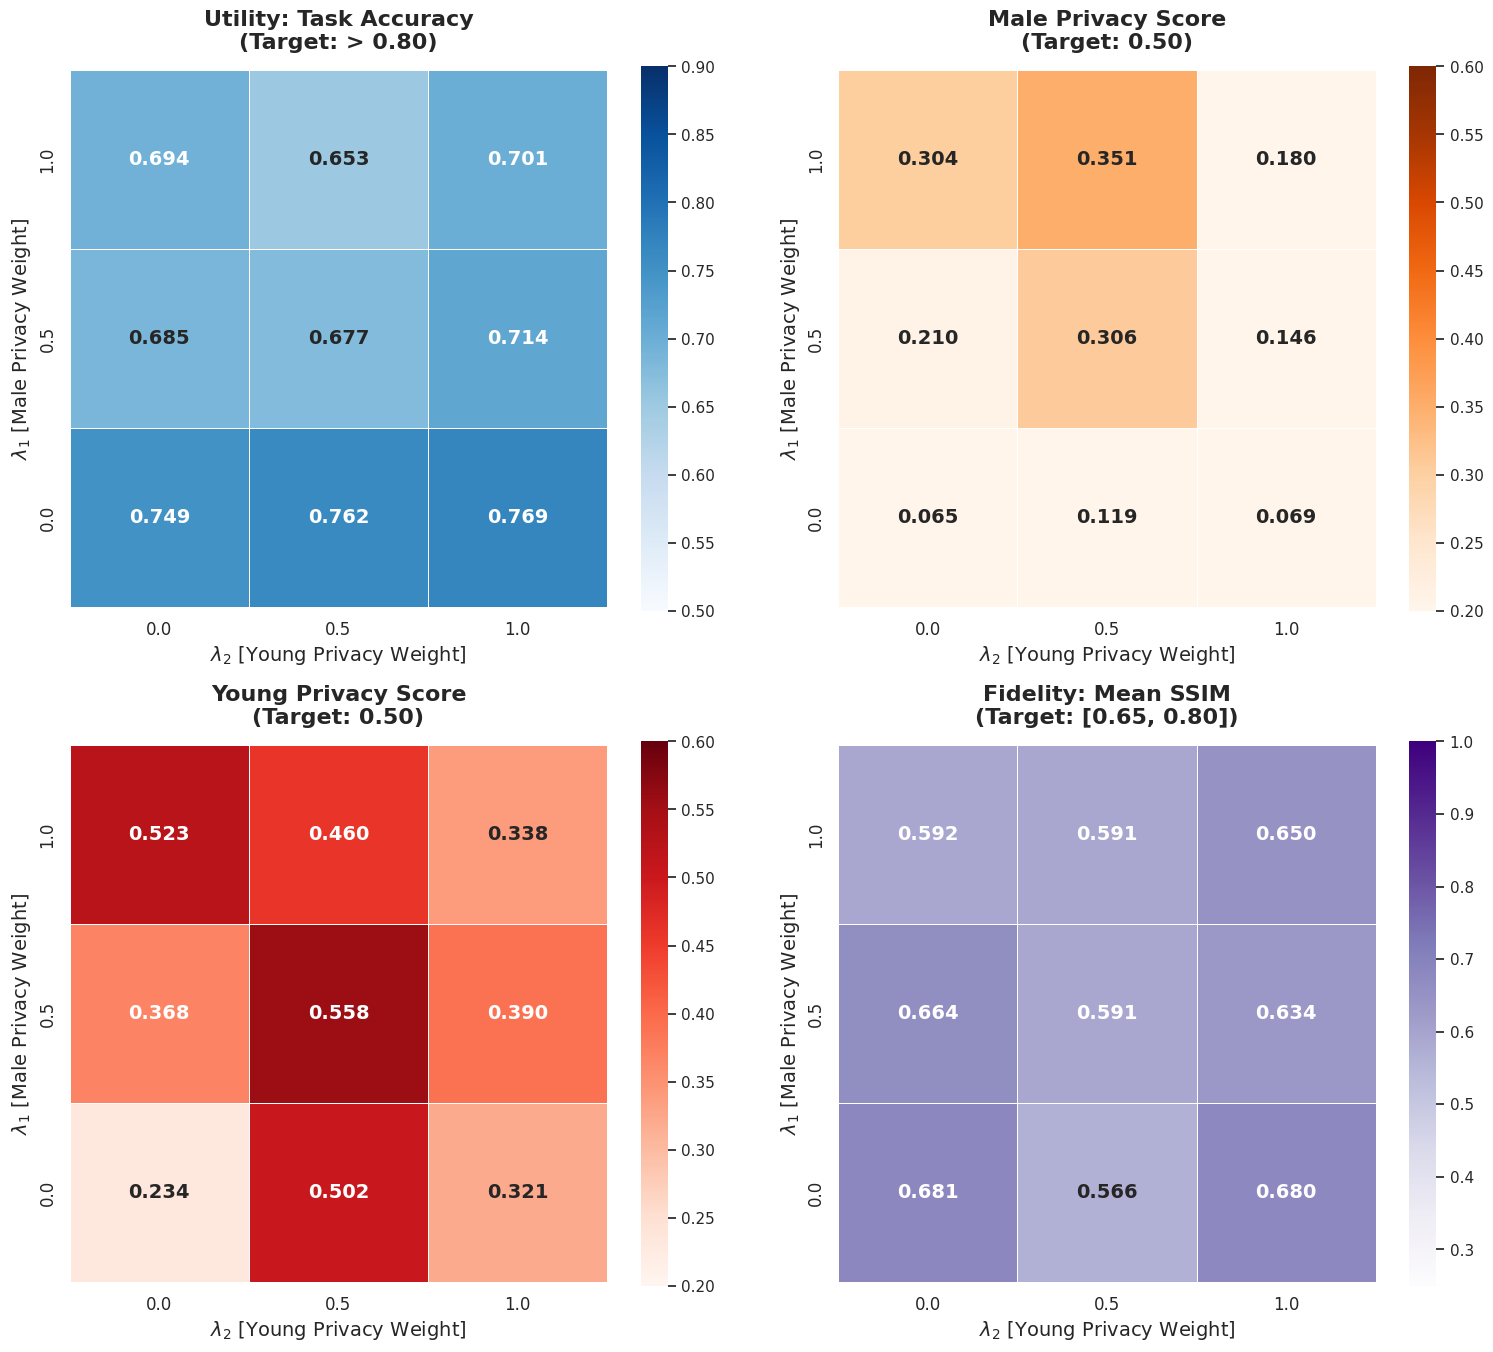


✅ High-resolution 3x3 heatmaps saved to: pareto_surface_3x3_heatmaps.pdf


In [25]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- 1. Load the Data ---
SWEEP_LOG = 'sweep_results_3x3_final.json'

# We check a few possible locations where Kaggle might have stored it
possible_paths = [
    f'/kaggle/working/{SWEEP_LOG}',
    SWEEP_LOG,
    f'./{SWEEP_LOG}'
]

sweep_data = None
for path in possible_paths:
    if os.path.exists(path):
        with open(path, 'r') as f:
            sweep_data = json.load(f)
        print(f"✅ Found data at: {path}")
        break

if sweep_data is None:
    print(f"❌ ERROR: {SWEEP_LOG} not found. Make sure the 3x3 sweep finished saving.")
else:
    # Convert to Pandas DataFrame for automatic reshaping
    df = pd.DataFrame(sweep_data)

    # --- 2. Data Reshaping ---
    # pivot() automatically recognizes this is now a 3x3 grid instead of 5x5.
    # sort_index(ascending=False) mathematically forces 0.0 to the bottom left.
    pivot_util = df.pivot(index='lambda1', columns='lambda2', values='cls_acc').sort_index(ascending=False)
    pivot_priv1 = df.pivot(index='lambda1', columns='lambda2', values='priv1_score').sort_index(ascending=False)
    pivot_priv2 = df.pivot(index='lambda1', columns='lambda2', values='priv2_score').sort_index(ascending=False)
    pivot_ssim = df.pivot(index='lambda1', columns='lambda2', values='ssim').sort_index(ascending=False)

    # --- 3. Plotting Setup ---
    fig, axes = plt.subplots(2, 2, figsize=(16, 14))
    sns.set_theme(style="white")

    # Helper function to keep heatmaps consistent
    def plot_heatmap(data, ax, title, cmap, fmt=".3f", vmin=None, vmax=None):
        sns.heatmap(data, ax=ax, annot=True, fmt=fmt, cmap=cmap, cbar=True,
                    vmin=vmin, vmax=vmax, linewidths=.5, square=True,
                    annot_kws={"size": 14, "weight": "bold"}) # Increased text size for 3x3 grid
        
        ax.set_title(title, fontsize=16, fontweight='bold', pad=15)
        # Raw strings (r"") prevent Python escape sequence warnings
        ax.set_xlabel(r"$\lambda_2$ [Young Privacy Weight]", fontsize=14)
        ax.set_ylabel(r"$\lambda_1$ [Male Privacy Weight]", fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=12)

    # --- 4. Render the Heatmaps ---
    
    # Top Left: Utility (Target: Maximize, ~0.82 baseline)
    plot_heatmap(pivot_util, axes[0, 0], 
                 'Utility: Task Accuracy\n(Target: > 0.80)', 
                 cmap='Blues', vmin=0.50, vmax=0.90)

    # Top Right: Male Privacy (Target: 0.50)
    plot_heatmap(pivot_priv1, axes[0, 1], 
                 'Male Privacy Score\n(Target: 0.50)', 
                 cmap='Oranges', vmin=0.20, vmax=0.60)

    # Bottom Left: Young Privacy (Target: 0.50)
    plot_heatmap(pivot_priv2, axes[1, 0], 
                 'Young Privacy Score\n(Target: 0.50)', 
                 cmap='Reds', vmin=0.20, vmax=0.60)

    # Bottom Right: SSIM (Target: Maximize, [0.65, 0.80])
    plot_heatmap(pivot_ssim, axes[1, 1], 
                 'Fidelity: Mean SSIM\n(Target: [0.65, 0.80])', 
                 cmap='Purples', vmin=0.25, vmax=1.00)

    # --- 5. Final Polish & Save ---
    plt.tight_layout(pad=3.0)
    
    # Save as PDF for high-resolution LaTeX/Word rendering
    output_path = 'pareto_surface_3x3_heatmaps.pdf'
    plt.savefig(output_path, format='pdf', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✅ High-resolution 3x3 heatmaps saved to: {output_path}")

**Below is reconstruction loss parameter = 2.0 instead of 20.0**

In [27]:
import os
import json
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

# --- 1. CONFIGURATION ---
# 💾 CHANGED: Saving to a new file specifically for the MSE=2.0 run
SWEEP_LOG = '/kaggle/working/sweep_results_3x3_mse2.json'

# A 3x3 Grid covers the extremes and the exact middle (9 total points)
LAMBDA_VALUES = [0.0, 0.5, 1.0] 

# 1 Epoch with 250 batches provides a fast but stable "stress test"
SWEEP_EPOCHS = 1  
BATCH_LIMIT = 250 

# --- 2. RESUME / CHECKPOINT LOGIC ---
if os.path.exists(SWEEP_LOG):
    with open(SWEEP_LOG, 'r') as f:
        sweep_results = json.load(f)
    # Map out what we've already done
    completed = {(r['lambda1'], r['lambda2']) for r in sweep_results}
    print(f"Resuming: {len(completed)}/9 points already finished.")
else:
    sweep_results = []
    completed = set()

total_points = len(LAMBDA_VALUES)**2
done = len(completed)

# --- 3. THE OPTIMIZED LOOP ---
for lam1 in LAMBDA_VALUES:
    for lam2 in LAMBDA_VALUES:
        if (lam1, lam2) in completed: 
            continue # Skip if we already trained this coordinate
        
        # 🟢 A. Reset GPU Memory to prevent Out-Of-Memory crashes
        tf.keras.backend.clear_session()
        gc.collect()
        
        done += 1
        
        # Balance Weights (Ensure they don't exceed 1.0 to prevent gradient explosion)
        total_lam = lam1 + lam2
        if total_lam > 1.0:
            eff_l1, eff_l2, util_w = lam1/total_lam, lam2/total_lam, 0.0
        else:
            eff_l1, eff_l2, util_w = lam1, lam2, 1.0 - total_lam

        print(f"\n[{done}/{total_points}] λ1={lam1:.2f}, λ2={lam2:.2f} | Util_w={util_w:.2f}")

        # 🟢 B. Build Models (Fresh init for every point to avoid cross-contamination)
        anon_s = build_anonymizer()
        cls_s  = build_classifier(trainable_base=False)
        adv1_s = build_adversary(name='Adv1_sw')
        adv2_s = build_adversary(name='Adv2_sw')

        # Load standard baselines (Ensure these variables point to your pre-trained weights)
        cls_s.load_weights(BASELINE_CKPT)
        adv1_s.load_weights(adv1_ckpt)
        adv2_s.load_weights(adv2_ckpt)

        opt = Adam(1e-4, clipnorm=1.0)

        # 🟢 C. Training Phase
        for epoch in range(SWEEP_EPOCHS):
            for imgs, tl, p1l, p2l in train_ds.take(BATCH_LIMIT):
                with tf.GradientTape() as tape:
                    an = anon_s(imgs, training=True)
                    
                    # Predictions
                    p1_preds = adv1_s(an, training=False)
                    p2_preds = adv2_s(an, training=False)
                    u_preds  = cls_s(an, training=False)
                    
                    # 1. Structural Fidelity (The Anchor)
                    ssim_val = tf.reduce_mean(tf.image.ssim(imgs, an, max_val=1.0))
                    ssim_loss = 1.0 - ssim_val
                    mse_loss = tf.reduce_mean(tf.square(imgs - an)) # Pixel-wise reconstruction
                    
                    # 2. Adversarial Privacy (Target 0.5)
                    targ = tf.fill(tf.shape(p1_preds), 0.5)
                    pl1 = bce(targ, p1_preds)
                    pl2 = bce(targ, p2_preds)
                    
                    # 3. Utility (Smiling detection)
                    ul = bce(tf.expand_dims(tl, 1), u_preds)
                    
                    # Combined Loss (Lightened MSE anchor: 2.0 instead of 20.0)
                    loss = (eff_l1 * pl1) + \
                           (eff_l2 * pl2) + \
                           (util_w * ul) + \
                           (ssim_loss * 5.0) + \
                           (mse_loss * 2.0) 
                
                grads = tape.gradient(loss, anon_s.trainable_variables)
                opt.apply_gradients(zip(grads, anon_s.trainable_variables))

        # 🟢 D. Evaluate & Auto-Save
        metrics = evaluate_on_test(anon_s, cls_s, adv1_s, adv2_s, test_ds)
        metrics.update({'lambda1': float(lam1), 'lambda2': float(lam2), 'util_weight': float(util_w)})
        
        sweep_results.append(metrics)

        # 💾 THE LIFESAVER: Save immediately after this point finishes
        with open(SWEEP_LOG, 'w') as f:
            json.dump(sweep_results, f, indent=2)
        
        # Cleanup objects to free GPU RAM
        del anon_s, cls_s, adv1_s, adv2_s
        print(f"   Saved: SSIM={metrics['ssim']:.3f} | Util={metrics['cls_acc']:.3f} | M-Priv={metrics['priv1_score']:.3f} | Y-Priv={metrics['priv2_score']:.3f}")

print(f"\n✅ 3x3 Pareto Sweep Complete. Safe and sound in {SWEEP_LOG}")


[1/9] λ1=0.00, λ2=0.00 | Util_w=1.00
   Saved: SSIM=0.702 | Util=0.697 | M-Priv=0.071 | Y-Priv=0.274

[2/9] λ1=0.00, λ2=0.50 | Util_w=0.50
   Saved: SSIM=0.643 | Util=0.730 | M-Priv=0.099 | Y-Priv=0.345

[3/9] λ1=0.00, λ2=1.00 | Util_w=0.00
   Saved: SSIM=0.616 | Util=0.700 | M-Priv=0.143 | Y-Priv=0.392

[4/9] λ1=0.50, λ2=0.00 | Util_w=0.50
   Saved: SSIM=0.673 | Util=0.701 | M-Priv=0.185 | Y-Priv=0.388

[5/9] λ1=0.50, λ2=0.50 | Util_w=0.00
   Saved: SSIM=0.578 | Util=0.687 | M-Priv=0.361 | Y-Priv=0.465

[6/9] λ1=0.50, λ2=1.00 | Util_w=0.00
   Saved: SSIM=0.609 | Util=0.685 | M-Priv=0.344 | Y-Priv=0.435

[7/9] λ1=1.00, λ2=0.00 | Util_w=0.00
   Saved: SSIM=0.572 | Util=0.671 | M-Priv=0.363 | Y-Priv=0.567

[8/9] λ1=1.00, λ2=0.50 | Util_w=0.00
   Saved: SSIM=0.590 | Util=0.692 | M-Priv=0.559 | Y-Priv=0.498

[9/9] λ1=1.00, λ2=1.00 | Util_w=0.00
   Saved: SSIM=0.636 | Util=0.716 | M-Priv=0.215 | Y-Priv=0.354

✅ 3x3 Pareto Sweep Complete. Safe and sound in /kaggle/working/sweep_results_3x3_

✅ Found data at: /kaggle/working/sweep_results_3x3_mse2.json


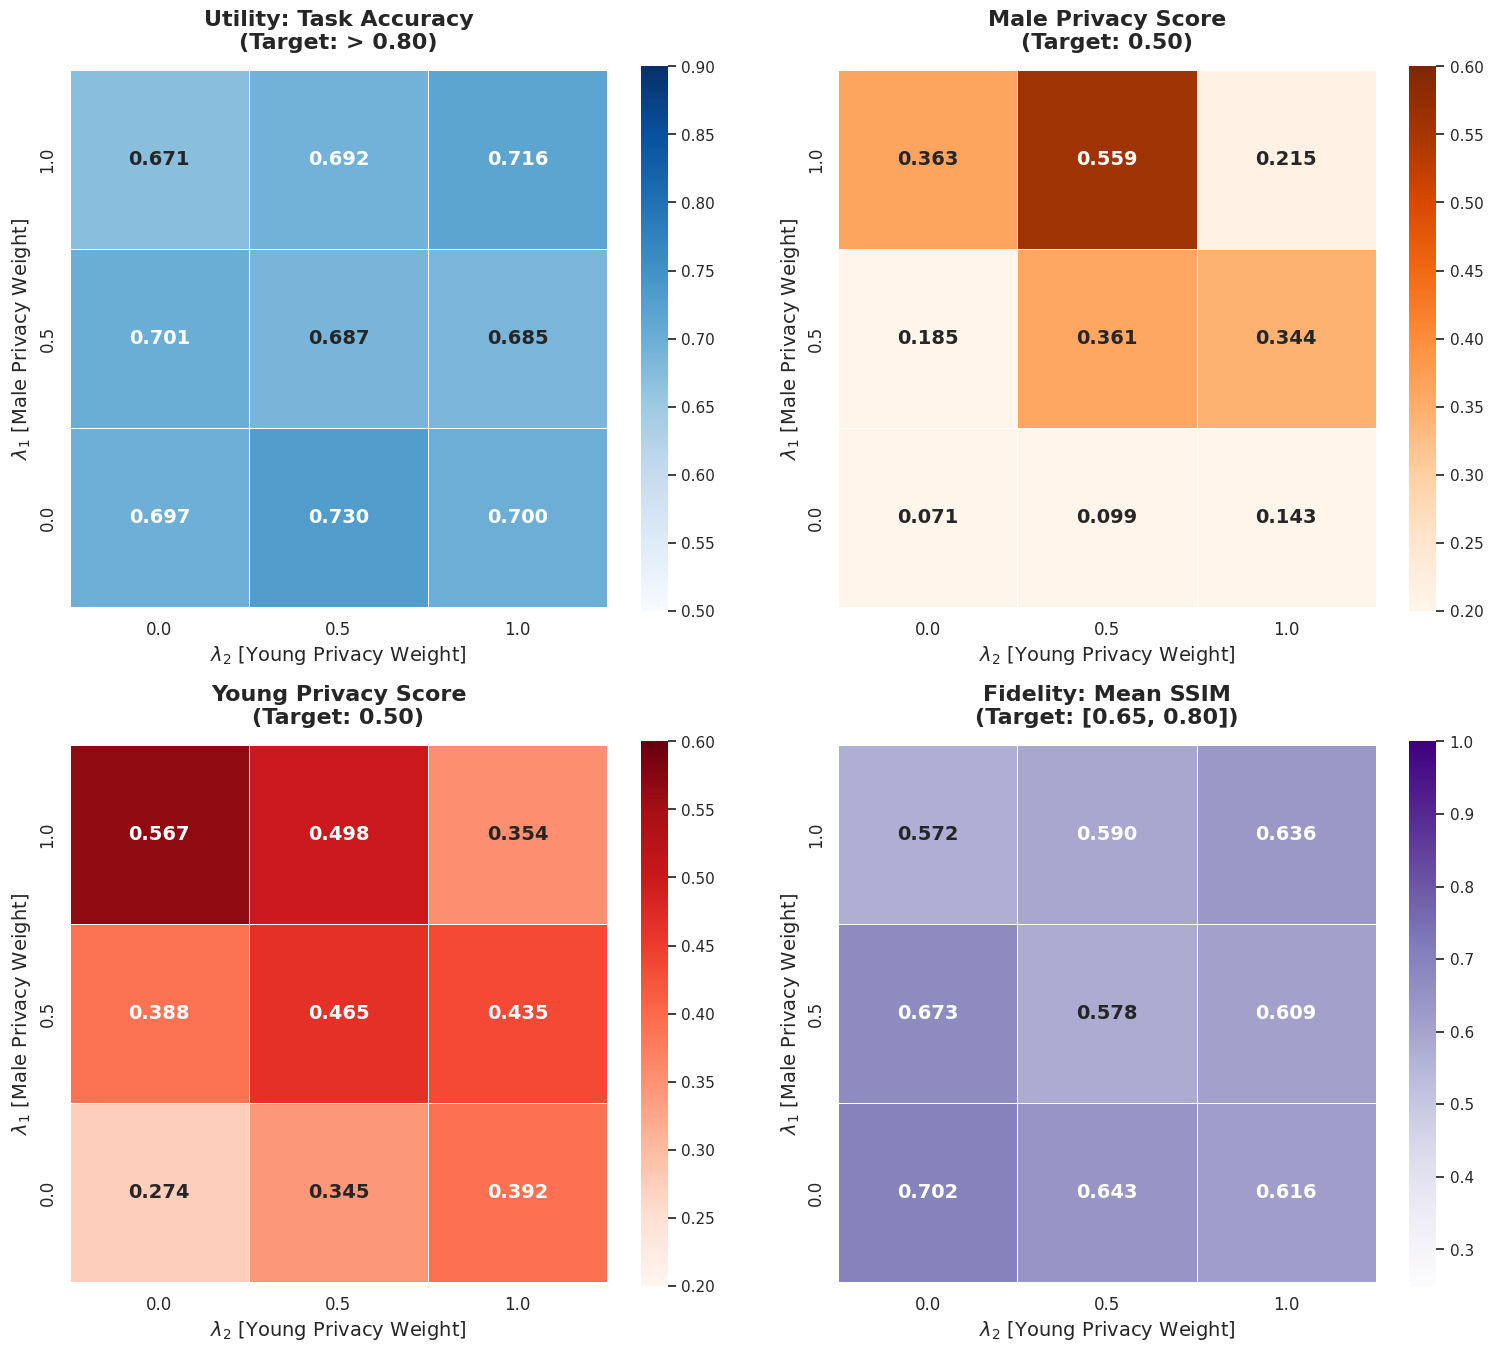


✅ High-resolution 3x3 heatmaps saved to: pareto_surface_3x3_heatmaps.pdf


In [28]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- 1. Load the Data ---
SWEEP_LOG = 'sweep_results_3x3_mse2.json'

# We check a few possible locations where Kaggle might have stored it
possible_paths = [
    f'/kaggle/working/{SWEEP_LOG}',
    SWEEP_LOG,
    f'./{SWEEP_LOG}'
]

sweep_data = None
for path in possible_paths:
    if os.path.exists(path):
        with open(path, 'r') as f:
            sweep_data = json.load(f)
        print(f"✅ Found data at: {path}")
        break

if sweep_data is None:
    print(f"❌ ERROR: {SWEEP_LOG} not found. Make sure the 3x3 sweep finished saving.")
else:
    # Convert to Pandas DataFrame for automatic reshaping
    df = pd.DataFrame(sweep_data)

    # --- 2. Data Reshaping ---
    # pivot() automatically recognizes this is now a 3x3 grid instead of 5x5.
    # sort_index(ascending=False) mathematically forces 0.0 to the bottom left.
    pivot_util = df.pivot(index='lambda1', columns='lambda2', values='cls_acc').sort_index(ascending=False)
    pivot_priv1 = df.pivot(index='lambda1', columns='lambda2', values='priv1_score').sort_index(ascending=False)
    pivot_priv2 = df.pivot(index='lambda1', columns='lambda2', values='priv2_score').sort_index(ascending=False)
    pivot_ssim = df.pivot(index='lambda1', columns='lambda2', values='ssim').sort_index(ascending=False)

    # --- 3. Plotting Setup ---
    fig, axes = plt.subplots(2, 2, figsize=(16, 14))
    sns.set_theme(style="white")

    # Helper function to keep heatmaps consistent
    def plot_heatmap(data, ax, title, cmap, fmt=".3f", vmin=None, vmax=None):
        sns.heatmap(data, ax=ax, annot=True, fmt=fmt, cmap=cmap, cbar=True,
                    vmin=vmin, vmax=vmax, linewidths=.5, square=True,
                    annot_kws={"size": 14, "weight": "bold"}) # Increased text size for 3x3 grid
        
        ax.set_title(title, fontsize=16, fontweight='bold', pad=15)
        # Raw strings (r"") prevent Python escape sequence warnings
        ax.set_xlabel(r"$\lambda_2$ [Young Privacy Weight]", fontsize=14)
        ax.set_ylabel(r"$\lambda_1$ [Male Privacy Weight]", fontsize=14)
        ax.tick_params(axis='both', which='major', labelsize=12)

    # --- 4. Render the Heatmaps ---
    
    # Top Left: Utility (Target: Maximize, ~0.82 baseline)
    plot_heatmap(pivot_util, axes[0, 0], 
                 'Utility: Task Accuracy\n(Target: > 0.80)', 
                 cmap='Blues', vmin=0.50, vmax=0.90)

    # Top Right: Male Privacy (Target: 0.50)
    plot_heatmap(pivot_priv1, axes[0, 1], 
                 'Male Privacy Score\n(Target: 0.50)', 
                 cmap='Oranges', vmin=0.20, vmax=0.60)

    # Bottom Left: Young Privacy (Target: 0.50)
    plot_heatmap(pivot_priv2, axes[1, 0], 
                 'Young Privacy Score\n(Target: 0.50)', 
                 cmap='Reds', vmin=0.20, vmax=0.60)

    # Bottom Right: SSIM (Target: Maximize, [0.65, 0.80])
    plot_heatmap(pivot_ssim, axes[1, 1], 
                 'Fidelity: Mean SSIM\n(Target: [0.65, 0.80])', 
                 cmap='Purples', vmin=0.25, vmax=1.00)

    # --- 5. Final Polish & Save ---
    plt.tight_layout(pad=3.0)
    
    # Save as PDF for high-resolution LaTeX/Word rendering
    output_path = 'pareto_surface_3x3_heatmaps.pdf'
    plt.savefig(output_path, format='pdf', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✅ High-resolution 3x3 heatmaps saved to: {output_path}")